> ## 🎤 강사 스크립트 · 이 강사용 노트북 사용법
>
> 이 노트북은 **학생용 `D28_Pipecat심화_실습.ipynb`의 모든 셀을 그대로 담고**, 사이사이에 **🎤 강사 스크립트 셀**을 끼워 넣은 것입니다. 수업 화면에는 학생용을, 강사 화면에는 이 노트북을 띄우세요.
>
> | 표시 | 뜻 |
> |---|---|
> | 🎯 | 이 블록에서 학생이 가져가야 할 한 가지 |
> | 🗣️ | 그대로 읽어도 되는 강사 멘트 |
> | 🍎 | 일상 비유 |
> | 🖥️ | 화면 시연 |
> | ❓ | 학생에게 던지는 질문 → 예상 답 |
> | 🆘 | 빈칸에서 막힌 학생에게 주는 힌트 |
> | ⚠️ | 자주 막히는 지점 · 오개념 · 오류 |
> | 🎧 | 반 전체가 같이 들을 소리 (스피커) |
> | ➡️ | 다음 블록으로 넘어가는 연결 멘트 |
>
> **오늘의 수업 방향**: D27의 파이프라인은 그대로 두고 **손잡이만 돌립니다**. 핵심 메시지는 **"VAD는 소리가 멈췄는지만 안다 → 할 말이 끝났는지는 턴 판단이 정한다 → 사용자가 말하면 비서는 곧바로 멈춘다(예외: 꼭 들려줄 안내) → 이 모든 것을 숫자로 잰다"** 입니다. 칠판에 쓰는 것은 세 줄: **`volume = (LUFS + 110) / 100`**, **`응답 = 턴 판단 + STT + LLM + 첫 문장 + TTS`**, **`턴 시작 → InterruptionFrame → 모두 멈춤`**.
>
> > 🍎 **하루를 꿰는 비유: 전화 상담원 교육.** 손님이 숨 고를 때 끼어들지 않기(턴 판단), 손님이 말을 시작하면 바로 입 다물기(끼어들기), 단 녹취 고지는 끝까지(Mute), 그리고 통화마다 응답 시간 재기(Metrics).
>
> > ⚠️ Part 3 · 4는 실제 시간으로 흐르는 WebSocket 통화라 셀마다 15 ~ 40초 걸립니다. 그 사이에 애니메이션을 보여 주세요.
>
> > 🔒 키는 Colab 보안 비밀에만. 과제 1의 본인 녹음은 노션에 올리지 않게 다시 안내.
>
> > 💡 정답 · 예상 출력 · 힌트는 이 노트북에만 있습니다. **학생에게 배포하지 마세요.**

> ## 🎤 강사 스크립트 · 하루 시간표와 수업 전 점검
>
> #### 하루 시간표 (50분 수업 + 10분 쉬는 시간)
> | 시간 | 교시 | 내용 | 빈칸 | 애니메이션 | 슬라이드 |
> |---|---|---|---|---|---|
> | 0:00–0:50 | 1교시 | 도입, Part 0 설치 · 복습 셀, Part 1 VAD 튜닝 | 1 · 2 | D28-1 · 2 · 3 | p.1 ~ 7 |
> | 1:00–1:50 | 2교시 | Part 2 Speech Timeout vs Smart Turn | 3 · 4 | D28-4 | p.8 ~ 11 |
> | 2:00–2:50 | 3교시 | Part 3 Interruption · 끼어들기 끄기 · Mute | 5 · 6 · 7 | D28-5 · 6 | p.12 ~ 15 |
> | 3:00–3:50 | 4교시 | Part 4 Metrics · UserBotLatencyObserver · 설정 비교, Part 5 정리 | 8 · 9 | D28-7 · 8 · 9 | p.16 ~ 20 |
>
> **진도가 밀릴 때 줄이는 순서** (빈칸 실습은 줄이지 않습니다)
> 1. Part 4 '설정별 비교' 셀(통화 3번, 약 45초)은 강사 시연만
> 2. Part 3의 B · C 통화 그림은 강사 화면으로만
> 3. Part 1 빈칸 2의 TV 크기 바꿔 보기 생략
>
> #### 수업 전 점검 (전날)
> - [ ] 처음부터 끝까지 한 번 실행(T4, 로컬 Qwen이면 약 15분). Part 1 · 2 표, Part 3 세 그림, Part 4 TTFB 표 캡처
> - [ ] **Edge TTS 소리 확인**: Part 0의 🎧 세 개가 사람 목소리로 나오는지(⚠️ 'Edge TTS 실패' 줄이 보이면 MMS로 돌아간 것)
> - [ ] **Smart Turn 확률표**(빈칸 3): '쉼 없이 끝까지'가 높고 '말하다 멈춤'이 낮게 나오는지. 합성 목소리 · 한국어라 뒤집힐 수 있음 → 그 자체를 토론 거리로
> - [ ] **끼어들기 A**: 그림에서 분홍 막대가 초록 막대 시작 직후 끊기는지. 안 끊기면 `barge_at`(2.0)을 1.0으로
> - [ ] 스피커 준비 (Part 0의 TV 섞인 소리, Part 3의 끊기는 안내를 반 전체가 듣기)
> - [ ] [animation.html](https://imguru-mooc.github.io/AI_Voice/day28/animation.html) · [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day28/worksheet.html) 탭 열기
>
> #### 오늘 학생들이 가장 많이 막히는 곳
> | 위치 | 증상 | 대응 |
> |---|---|---|
> | Part 1 | `VAD stop_secs (…) differs from the recommended default` 경고 | 정상: Pipecat이 0.2초 기준으로 지연 수치를 맞춰 둠. 오늘은 일부러 바꿈 |
> | 빈칸 2 | TV 크기에 따라 0.75로도 TV가 잡힘 | `TV_GAIN`을 0.02로 낮추거나 0.85를 보기. 표의 volume 값 사이에 기준을 두라고 안내 |
> | 빈칸 3 | `_predict_endpoint`가 뭐냐는 질문 | 내부용 메서드(밑줄). 파이프라인에서는 전략이 부름. 오늘은 속을 보려고 직접 호출 |
> | Part 3 | 반응 시간이 `None` | 끼어들기 전에 안내가 끝남(TTS가 빠르거나 짧음) → `barge_at` 줄이기 |
> | Part 3 | 셀이 40초 이상 | 로컬 Qwen 답이 길어짐. `max_new_tokens` 낮추기 또는 키 사용 |
> | Part 4 | TTFB 표에 LocalLLM이 없음 | 빈칸 9 셀을 먼저 실행했는지 확인(make_llm이 새 LocalLLM을 써야 함) |

# D28. Pipecat 심화: VAD 튜닝 · Turn Detection · Interruption(Barge-in) · Metrics  —  🎤 강사용

**음성 AI 전문가 과정 (160h) | 6주차 M6 실시간 음성 파이프라인 (Pipecat · LiveKit) | 4시간**

## 학습 목표
1. Silero VAD의 **네 가지 손잡이**(`confidence` · `start_secs` · `stop_secs` · `min_volume`)를 바꾸며, 말 중간 쉼과 배경 소리(TV)에 VAD가 어떻게 반응하는지 잰다.
2. '조용하면 끝'(**Speech Timeout**)과 '말을 듣고 판단'(**Smart Turn**) 두 턴 판단 방법을, 중간에 쉬는 말 한 마디로 비교한다.
3. 비서가 말하는 도중 사용자가 끼어들면(**Barge-in**) `InterruptionFrame`이 파이프라인을 어떻게 멈추는지 보고, **반응 시간**을 잰다.
4. 끼어들기를 **끄거나**(`enable_interruptions=False`), 첫 안내(녹취 고지 등)가 끝날 때까지 **사용자 말을 막는**(Mute) 설정을 비교한다.
5. **Metrics**(`MetricsFrame`의 TTFB · 처리 시간)와 `UserBotLatencyObserver`로 '말 끝 → 첫 소리'를 서비스별로 나눠 재고, 직접 만든 LLM 서비스에도 TTFB를 붙인다.

## 오늘의 실습 흐름
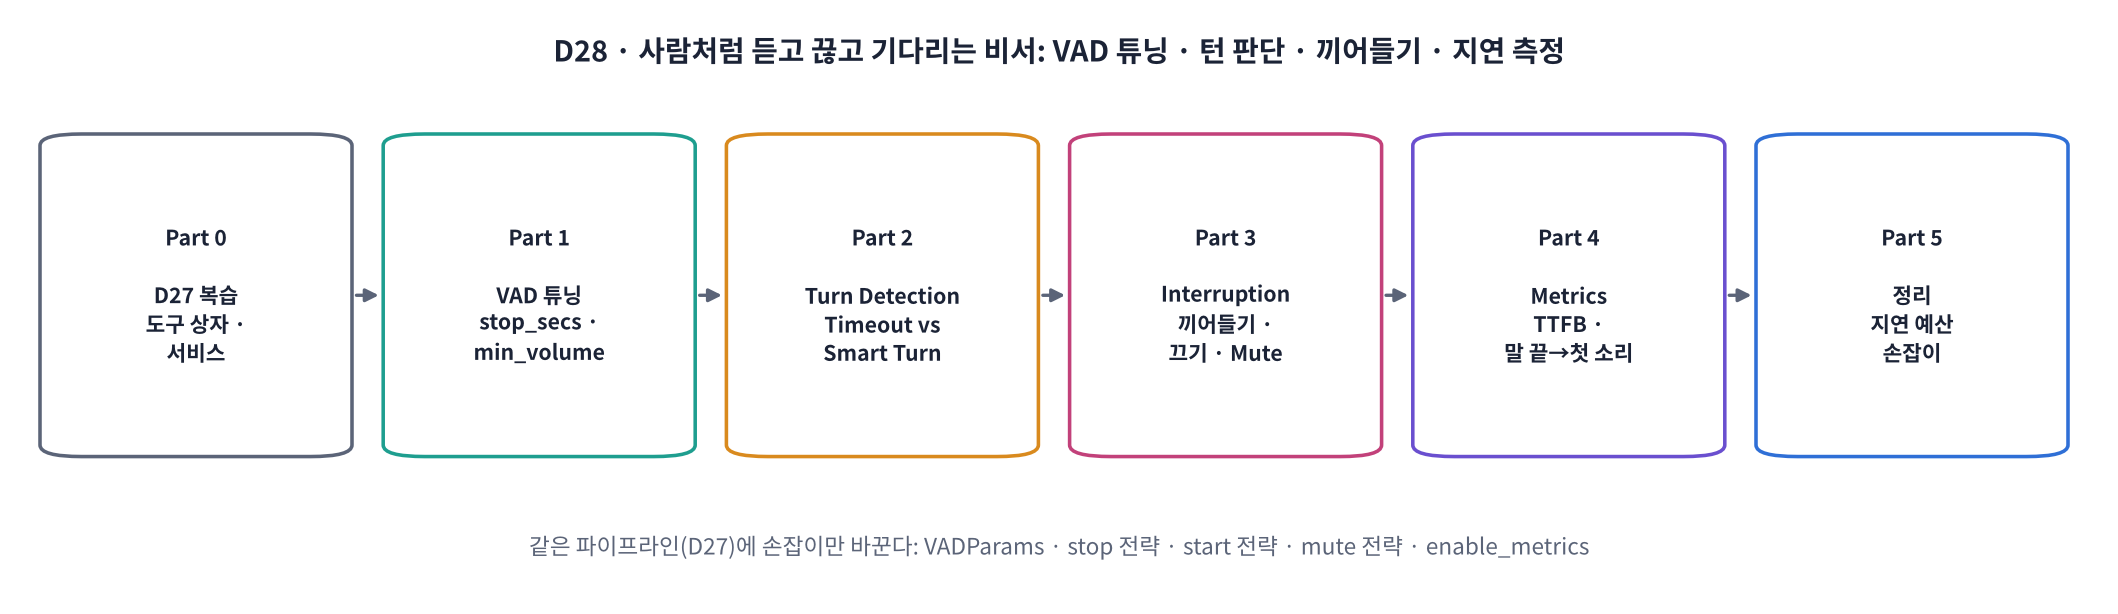

| 교시 | 내용 | 실습 | 산출물 |
|---|---|---|---|
| 1교시 | D27 복습(도구 상자), VAD의 네 손잡이: 쉼 · 배경 소리 | Part 0 ~ 1, 워크시트 1교시 | stop_secs별 구간 표 · min_volume별 TV 소리 표 |
| 2교시 | Turn Detection: Speech Timeout vs Smart Turn | Part 2, 워크시트 2교시 | Smart Turn 확률 표 · 두 방법의 턴 나눔 비교 |
| 3교시 | Interruption(Barge-in) · 끼어들기 끄기 · Mute | Part 3, 워크시트 3교시 | 세 설정의 말하기 타임라인 · 반응 시간 |
| 4교시 | Metrics · UserBotLatencyObserver · 설정별 지연 비교, 정리 | Part 4 ~ 5, 워크시트 4교시 | 서비스별 TTFB 표 · 턴별 지연 · 설정 비교표 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day28/animation.html) | VAD 손잡이(D28-2 · 3) · 턴 판단(D28-4) · 끼어들기(D28-5 · 6) · 지연 분해(D28-7 · 8) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day28/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 위에서부터 차례로 실행합니다. Part 0의 **D27 복습 셀**에 어제 만든 작업자 · 서비스 · 도구가 모두 들어 있습니다.
- 🧩 **빈칸 실습** 셀은 `____`를 채우고 실행하면 ✅ 또는 ❌가 나옵니다. 🔑 **정답 및 해설 보기**를 누르면 정답이 펼쳐집니다.
- ✏️ 표시 셀은 값을 **직접 바꿔** 다시 실행해 보는 셀입니다.
- ⏳ Part 3 · 4는 D27 Part 6처럼 **실제 시간으로 흐르는 통화**(WebSocket)를 돌리므로 셀 하나에 15 ~ 40초가 걸립니다.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🎧 **들어 보기** | 소리로 확인 |

> ⚙️ **런타임 → T4 GPU**. 🔑 **API 키 (선택, D22 · D27과 같음)**: `ANTHROPIC_API_KEY` · `OPENAI_API_KEY` · `GEMINI_API_KEY` 중 하나가 있으면 그 LLM을, 없으면 **로컬 Qwen3**를 씁니다. 키는 화면에 출력하지 않습니다.
>
> 🔊 TTS는 **Edge 신경망 음성**(인터넷 필요, 실패하면 MMS-TTS로 자동 전환)입니다. 🔒 WebSocket 서버는 **이 Colab 안(127.0.0.1)** 에서만 열립니다.

> 🎬 **애니메이션 D28-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#flow) — Part 1~5 로드맵과 시간 계획

> ## 🎤 강사 스크립트 · 도입  ⏱️ 5분
>
> 🎯 **어제 비서는 '조용하면 끝, 끝나면 답'만 알았다. 오늘은 사람처럼 기다리고, 끊기면 멈추고, 그 모든 걸 잰다.**
>
> 🗣️ "어제 비서에게 '다음 주 수요일… 오후 두 시에'라고 쉬어 가며 말하면 어떻게 될까요? 쉬는 사이에 '몇 시요?' 하고 끼어듭니다. 반대로 비서가 길게 안내하는데 '잠깐만요' 하면? 어제 비서는 멈추는지조차 확인하지 않았죠. 오늘 이 두 가지를 고치고, 고친 효과를 숫자로 잽니다."
>
> 🖥️ [D28-1 오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#flow)

## Part 0. 준비 (D27과 같음 + 복습 셀)

> 🛠️ D27과 같은 설치입니다(`pipecat-ai==1.15.0` 고정, Edge TTS 추가). Smart Turn 모델(`smart-turn-v3.2`, 약 8 MB)과 Silero VAD는 **Pipecat 패키지 안에 들어 있어** 따로 내려받지 않습니다.

> ## 🎤 강사 스크립트 · Part 0  ⏱️ 8분
>
> 🖥️ 설치(1 ~ 2분) 동안 슬라이드 p.2 '오늘 답할 질문'.
>
> 🗣️ "Smart Turn 모델(8 MB)과 Silero VAD는 Pipecat 안에 들어 있어서 따로 내려받지 않습니다."

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1 ~ 2분)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt "pipecat-ai[websocket]==1.15.0"
!pip install -q -c colab_constraints.txt uroman edge-tts
print("✅ 설치 완료")

In [ ]:
import os, re, sys, json, time, random, socket, asyncio, warnings, logging
from dataclasses import dataclass
import numpy as np
import pandas as pd
import librosa
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio, display, Markdown
import importlib.metadata as md
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)
from loguru import logger                                # Pipecat은 loguru로 로그를 남김 → 경고 이상만 보이게
logger.remove(); logger.add(sys.stderr, level="WARNING")

from pipecat.frames.frames import (Frame, SystemFrame, DataFrame, ControlFrame, StartFrame, EndFrame, CancelFrame,
    TextFrame, LLMTextFrame, TranscriptionFrame, InputAudioRawFrame, OutputAudioRawFrame, TTSAudioRawFrame, TTSSpeakFrame,
    TTSStartedFrame, TTSStoppedFrame, ErrorFrame, InterruptionFrame, LLMContextFrame, LLMFullResponseStartFrame,
    LLMFullResponseEndFrame, VADUserStartedSpeakingFrame, VADUserStoppedSpeakingFrame, UserStartedSpeakingFrame,
    UserStoppedSpeakingFrame, BotStartedSpeakingFrame, BotStoppedSpeakingFrame)
from pipecat.processors.frame_processor import FrameProcessor, FrameDirection
from pipecat.pipeline.pipeline import Pipeline
from pipecat.pipeline.worker import PipelineWorker, PipelineParams
from pipecat.workers.runner import WorkerRunner
from pipecat.observers.base_observer import BaseObserver, FramePushed

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
SR = 16000
print(" · ".join(f"{p} {md.version(p)}" for p in ["pipecat-ai", "torch", "transformers", "websockets"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 (CPU로도 가능)")

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if GPU: torch.cuda.manual_seed_all(s)

def to_np(y):
    y = y.detach().cpu().numpy() if torch.is_tensor(y) else np.asarray(y)
    return y.reshape(-1).astype(np.float32)

def play(y, sr=SR, label=""):
    y = to_np(y)
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    if len(y): display(Audio(y, rate=sr))
    else: print("   (소리 없음: 위의 경고 · 오류를 확인하세요)")

def silence(sec, sr=SR):
    return np.zeros(int(sec * sr), np.float32)

def free_port():                                         # 비어 있는 포트 번호 하나
    s = socket.socket(); s.bind(("127.0.0.1", 0)); p = s.getsockname()[1]; s.close(); return p

# D16 정규화 (숫자 → 읽는 말): TTS 바로 앞에서 씀
DIGITS = "영일이삼사오육칠팔구"
def sino(n):
    if n == 0: return "영"
    out = ""
    for big in ["", "만", "억", "조"]:
        chunk, n = n % 10000, n // 10000; s = ""
        for i, unit in enumerate(["", "십", "백", "천"]):
            d, chunk = chunk % 10, chunk // 10
            if d: s = ("" if d == 1 and i > 0 else DIGITS[d]) + unit + s
        if s: out = ("" if s == "일" and big == "만" else s) + big + out
        if n == 0: break
    return out
ONES = ["", "한", "두", "세", "네", "다섯", "여섯", "일곱", "여덟", "아홉"]
TENS = ["", "열", "스물", "서른", "마흔", "쉰", "예순", "일흔", "여든", "아흔"]
def native(n): return sino(n) if not 0 < n < 100 else ("스무" if n == 20 else TENS[n // 10] + ONES[n % 10])
NATIVE_COUNTERS = ["시간", "개", "명", "살", "마리", "권", "잔", "병", "장", "달", "시"]
def normalize_ko(t):
    t = re.sub(r"(\d+)\s*(" + "|".join(NATIVE_COUNTERS) + ")", lambda m: native(int(m.group(1))) + " " + m.group(2), t)
    t = re.sub(r"(\d+)\s*%", lambda m: sino(int(m.group(1))) + " 퍼센트", t)
    t = re.sub(r"\d+", lambda m: sino(int(m.group(0))), t)
    return re.sub(r"\s+", " ", t).strip()
print(normalize_ko("오후 2시에 3명, 주차는 2시간 무료, 할인 10%"))

In [ ]:
# 🔊 모델 준비 (D27과 같음) + 오늘의 실험 소리: 쉼이 있는 말 · 말하다 만 문장 · 끼어드는 말 · 배경 TV · 안내 멘트
from transformers import AutoTokenizer, VitsModel, WhisperProcessor, WhisperForConditionalGeneration
import uroman as ur
tts_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kor")
tts_model = VitsModel.from_pretrained("facebook/mms-tts-kor").to(DEVICE).eval()
U = ur.Uroman()
ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME)
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()

import functools, tempfile
VOICE_BOT, VOICE_USER = "ko-KR-SunHiNeural", "ko-KR-InJoonNeural"   # ✏️ Edge 신경망 음성: 비서 · 사용자 대역
TTS_ENGINE = "edge"                                      # 인터넷 · 서비스 문제로 실패하면 자동으로 "mms"(예비)

@functools.lru_cache(maxsize=512)                        # 같은 문장은 다시 요청하지 않음
def _edge_tts(text, voice):
    import edge_tts
    fd, path = tempfile.mkstemp(suffix=".mp3"); os.close(fd)
    try:
        edge_tts.Communicate(text, voice).save_sync(path)
        return librosa.load(path, sr=SR)[0].astype(np.float32)   # MP3 24 kHz → 16 kHz
    finally:
        os.remove(path)

def _mms_tts(text, seed=0):                              # 예비: MMS-TTS 한국어 VITS (D16)
    set_seed(seed)
    enc = tts_tok(U.romanize_string(text), return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        return to_np(tts_model(**enc).waveform[0])

def tts(text, seed=0, voice=None):                       # 글자 → 16 kHz 소리: Edge 신경망 음성, 실패하면 MMS-TTS
    global TTS_ENGINE
    if TTS_ENGINE == "edge":
        try:
            return _edge_tts(text, voice or VOICE_BOT).copy()
        except Exception as e:
            print(f"⚠️ Edge TTS 실패 → MMS-TTS로 전환 ({type(e).__name__}: {str(e)[:80]})"); TTS_ENGINE = "mms"
    return _mms_tts(text, seed)

def user_tts(text, seed=0):                              # 사용자 대역 목소리: 비서와 다른 목소리 (MMS 예비일 때는 3반음 낮춰 구분)
    y = tts(text, seed=seed, voice=VOICE_USER)
    return librosa.effects.pitch_shift(y, sr=SR, n_steps=-3) if TTS_ENGINE == "mms" else y

def stt(y):                                              # 16 kHz 소리 → 글자
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=96)
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

def make_voice(text):                                    # 앞 0.5초 · 뒤 1초 조용함을 붙인 '사용자 말'
    y = np.concatenate([silence(0.5), user_tts(text), silence(1.0)]).astype(np.float32)
    return y / (np.abs(y).max() + 1e-9) * 0.8

def scene(*parts, tail=1.0):                             # 소리 조각과 '조용함(초)'을 이어 붙인 사용자 말 한 장면
    ys = [silence(0.5)] + [silence(p) if isinstance(p, (int, float)) else p for p in parts] + [silence(tail)]
    y = np.concatenate(ys).astype(np.float32)
    return y / (np.abs(y).max() + 1e-9) * 0.8

A, B = "다음 주 수요일", "오후 두 시에 스케일링 예약하고 싶어요"
PAUSE = 0.9                                              # ✏️ 말 중간 쉼(초)
PAUSED = scene(user_tts(A), PAUSE, user_tts(B))          # "다음 주 수요일 … (쉼) … 오후 두 시에 스케일링 예약하고 싶어요"
FULL = scene(user_tts(A + " " + B))                      # 쉼 없이 끝까지 말함
CUT = scene(user_tts("다음 주 수요일 오후 두 시에"))      # 말을 하다 만 상태 (문장이 안 끝남)
INTERRUPT = make_voice("잠깐만요, 예약만 할게요")          # 비서 말 도중 끼어드는 말
TV = tts("오늘의 날씨입니다 내일은 전국에 비가 오겠습니다", voice="ko-KR-HyunsuMultilingualNeural")
TV = TV / (np.abs(TV).max() + 1e-9)                      # 배경 TV 소리 (아래에서 작게 섞음)
GREET = ("안녕하세요, 한빛치과입니다. 이 통화는 서비스 품질을 위해 녹음됩니다. 오늘 진료는 오후 여섯 시까지이고, "
         "점심시간은 한 시부터 두 시까지입니다. 주차는 건물 지하에 두 시간 무료입니다. 무엇을 도와드릴까요?")
SAY1, SAY2 = "안녕하세요 한빛치과죠 다음 주 수요일 오후 두 시에 스케일링 예약하고 싶어요", "네 이름은 김민준이에요"
VOICE1, VOICE2 = make_voice(SAY1), make_voice(SAY2)     # D27과 같은 두 마디 (Part 4)
play(PAUSED, SR, f"쉼({PAUSE}초)이 있는 말"); play(CUT, SR, "말하다 만 문장"); play(INTERRUPT, SR, "끼어드는 말")
print("받아쓰기 확인:", stt(PAUSED), "/", stt(CUT))

> ## 🎤 강사 스크립트 · 오늘의 실험 소리  ⏱️ 4분
>
> 🎧 세 개: 쉼(0.9초)이 있는 말 · 말하다 만 문장 · 끼어드는 말. "쉼이 꽤 길죠? 실제로 사람은 생각하며 이만큼 쉽니다."
>
> ✅ 받아쓰기 두 줄이 대체로 맞으면 OK.

In [ ]:
# 🔑 LLM 고르기 (D22와 같음): 키가 있으면 클라우드, 없으면 로컬 Qwen3
def secret(name):
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v: return v
    except Exception:
        pass
    return os.environ.get(name) or None

MODELS = {"claude": "claude-haiku-5-5",                 # ✏️ 모델 이름은 수업 당일 각 회사 문서에서 확인
          "openai": "gpt-6-luna",
          "gemini": "gemini-3.5-flash-lite",
          "local": "Qwen/Qwen3-1.7B" if GPU else "Qwen/Qwen3-0.6B"}
KEYS = {"claude": "ANTHROPIC_API_KEY", "openai": "OPENAI_API_KEY", "gemini": "GEMINI_API_KEY"}
BASE_URLS = {"claude": "https://api.anthropic.com/v1/",                      # 세 회사 모두 'OpenAI 호환' 주소를 제공
             "openai": None,
             "gemini": "https://generativelanguage.googleapis.com/v1beta/openai/"}
AVAILABLE = [p for p in ["claude", "openai", "gemini"] if secret(KEYS[p])] + ["local"]
PROVIDER = AVAILABLE[0]                                  # ✏️ 바꿔 보기: "local" 등

if PROVIDER == "local":
    from transformers import AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(MODELS["local"])
    llm_model = AutoModelForCausalLM.from_pretrained(MODELS["local"], dtype=torch.float16 if GPU else torch.float32).to(DEVICE).eval()

SYSTEM = ("당신은 한빛치과의 전화 예약 도우미입니다. 음성으로 답하므로 한두 문장의 짧은 구어체로 말하고, "
          "목록 · 기호 · 이모지는 쓰지 않습니다. 예약에는 날짜 · 시간 · 진료 · 이름이 필요하며, 빠진 것이 있으면 하나씩 물어봅니다.")
print("쓸 수 있는 LLM:", AVAILABLE, "→ 오늘 쓸 LLM:", PROVIDER, MODELS[PROVIDER])

> ## 🎤 강사 스크립트 · LLM 고르기  ⏱️ 1분
>
> D27과 같음. 키가 없으면 local.

In [ ]:
# 🧰 D27 복습 셀: 도구 상자 · 서비스 · Serializer · 조립 함수 (어제 만든 것 + 오늘 쓸 손잡이)
from pipecat.frames.frames import MetricsFrame, OutputTransportMessageUrgentFrame
from pipecat.services.stt_service import SegmentedSTTService
from pipecat.services.tts_service import TTSService
from pipecat.services.settings import STTSettings, TTSSettings
from pipecat.services.openai.llm import OpenAILLMService
from pipecat.processors.audio.vad_processor import VADProcessor
from pipecat.processors.aggregators.llm_context import LLMContext
from pipecat.processors.aggregators.llm_response_universal import LLMContextAggregatorPair, LLMUserAggregatorParams
from pipecat.audio.vad.silero import SileroVADAnalyzer
from pipecat.audio.vad.vad_analyzer import VADParams
from pipecat.turns.user_turn_strategies import UserTurnStrategies
from pipecat.turns.user_start.vad_user_turn_start_strategy import VADUserTurnStartStrategy
from pipecat.turns.user_start.transcription_user_turn_start_strategy import TranscriptionUserTurnStartStrategy
from pipecat.turns.user_stop.speech_timeout_user_turn_stop_strategy import SpeechTimeoutUserTurnStopStrategy
from pipecat.serializers.base_serializer import FrameSerializer
from pipecat.transports.websocket.server import SingleClientWebsocketServerTransport, SingleClientWebsocketServerParams
from pipecat.transcriptions.language import Language
from pipecat.utils.time import time_now_iso8601
from websockets.asyncio.client import connect
from threading import Thread
from transformers import TextIteratorStreamer

QUIET = (InputAudioRawFrame, OutputAudioRawFrame)
class Recorder(FrameProcessor):                          # D27: 지나가는 Frame을 적고 그대로 넘기는 작업자
    def __init__(self, label="기록", **kwargs):
        super().__init__(**kwargs)
        self.label, self.rows, self.audio, self.t0, self.seen, self.marks = label, [], bytearray(), time.perf_counter(), {}, []
    async def process_frame(self, frame, direction):
        await super().process_frame(frame, direction)
        if isinstance(frame, OutputAudioRawFrame): self.audio += frame.audio
        if isinstance(frame, LLMFullResponseStartFrame): self.marks.append(len(self.audio))
        if not isinstance(frame, QUIET) or not any(r["Frame"] == type(frame).__name__ for r in self.rows[-1:]):
            self.rows.append(dict(시각=round(time.perf_counter() - self.t0, 3), 위치=self.label, Frame=type(frame).__name__,
                                  방향=direction.name, 내용=getattr(frame, "text", None) or ""))
        self.seen.setdefault(type(frame), asyncio.Event()).set()
        await self.push_frame(frame, direction)
    def table(self):
        return pd.DataFrame(self.rows)

async def run_frames(processors, frames=(), feed=None, observers=(), timeout=90, metrics=False):   # D27 + metrics 켜기
    worker = PipelineWorker(Pipeline(list(processors)), params=PipelineParams(audio_in_sample_rate=SR, audio_out_sample_rate=SR,
                            enable_metrics=metrics, enable_usage_metrics=metrics), observers=list(observers), enable_rtvi=False,
                            idle_timeout_secs=None, cancel_timeout_secs=3)
    runner = WorkerRunner(handle_sigint=False); await runner.add_workers(worker)
    t0 = time.perf_counter(); job = asyncio.ensure_future(runner.run())
    await worker.queue_frames(list(frames))
    if feed: await feed(worker)
    await worker.queue_frame(EndFrame())
    done, _ = await asyncio.wait({job}, timeout=timeout)
    if not done: await runner.cancel(); await job
    return dict(정상종료=bool(done), 걸린시간_초=round(time.perf_counter() - t0, 2))

def mic(*voices):                                        # D27: 20 ms 조각을 실시간 속도로 흘려보내는 가짜 마이크
    async def feed(worker):
        for y in voices:
            pcm = (np.clip(y, -1, 1) * 32767).astype(np.int16); t0 = time.perf_counter()
            for k, i in enumerate(range(0, len(pcm), 320)):
                await worker.queue_frame(InputAudioRawFrame(audio=pcm[i:i + 320].tobytes(), sample_rate=SR, num_channels=1))
                await asyncio.sleep(max(0, t0 + (k + 1) * 0.02 - time.perf_counter()))
    return feed

class FlowLog(BaseObserver):                             # D27: 상자가 처음 나온 순간을 기록하는 Observer
    def __init__(self, **kwargs):
        super().__init__(**kwargs); self.rows, self.t0 = [], time.perf_counter()
    async def on_push_frame(self, data: FramePushed):
        f = data.frame
        if isinstance(f, (InputAudioRawFrame, OutputAudioRawFrame)) or not data.first_push: return
        self.rows.append(dict(t=round(time.perf_counter() - self.t0, 3), 보낸쪽=data.source.name, Frame=type(f).__name__,
                              방향=data.direction.name, 내용=getattr(f, "text", None)))
    def table(self):
        return pd.DataFrame(self.rows)

class WhisperSTT(SegmentedSTTService):                   # D27 빈칸 5
    def __init__(self, **kwargs):
        super().__init__(settings=STTSettings(model=ASR_NAME, language=Language.KO), ttfs_p99_latency=1.0, **kwargs)
    def can_generate_metrics(self): return True          # 오늘 추가: Metrics(TTFB) 보고 켜기
    @property
    def wants_wav_segments(self): return False
    async def run_stt(self, audio: bytes):
        text = await asyncio.to_thread(stt, np.frombuffer(audio, np.int16).astype(np.float32) / 32768)
        yield TranscriptionFrame(text=text, user_id="", timestamp=time_now_iso8601())

class KoTTS(TTSService):                                 # D27 빈칸 6
    def __init__(self, **kwargs):
        super().__init__(sample_rate=SR, push_start_frame=True, push_stop_frames=True,
                         settings=TTSSettings(model="edge-tts", voice=VOICE_BOT, language=None), **kwargs)
    def can_generate_metrics(self): return True          # 오늘 추가
    async def run_tts(self, text: str, context_id: str):
        y = await asyncio.to_thread(tts, normalize_ko(text))
        yield TTSAudioRawFrame(audio=(np.clip(y, -1, 1) * 32767).astype(np.int16).tobytes(), sample_rate=SR, num_channels=1, context_id=context_id)

class LocalLLM(FrameProcessor):                          # D27 빈칸 7 (Part 4에서 Metrics를 붙인 판으로 다시 정의)
    def __init__(self, generate, system_instruction="", **kwargs):
        super().__init__(**kwargs); self.generate = generate
        self.system = [{"role": "system", "content": system_instruction}] if system_instruction else []
    async def process_frame(self, frame, direction):
        await super().process_frame(frame, direction)
        if isinstance(frame, LLMContextFrame):
            await self.push_frame(LLMFullResponseStartFrame())
            it = self.generate(self.system + frame.context.get_messages())
            while (piece := await asyncio.to_thread(next, it, None)) is not None:
                if piece: await self.push_frame(LLMTextFrame(text=piece))
            await self.push_frame(LLMFullResponseEndFrame())
        else:
            await self.push_frame(frame, direction)

def qwen_stream(messages):
    text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    enc = tok(text, return_tensors="pt").to(DEVICE)
    streamer = TextIteratorStreamer(tok, skip_prompt=True, skip_special_tokens=True)
    Thread(target=llm_model.generate, kwargs=dict(**enc, max_new_tokens=80, do_sample=False, repetition_penalty=1.1, streamer=streamer)).start()
    return iter(streamer)

def make_llm():
    if PROVIDER == "local":
        return LocalLLM(qwen_stream, system_instruction=SYSTEM)
    return OpenAILLMService(api_key=secret(KEYS[PROVIDER]), base_url=BASE_URLS[PROVIDER],
                            settings=OpenAILLMService.Settings(model=MODELS[PROVIDER], system_instruction=SYSTEM))

class RawPCMSerializer(FrameSerializer):                 # D27 빈칸 9
    async def serialize(self, frame):
        return frame.audio if isinstance(frame, OutputAudioRawFrame) else None
    async def deserialize(self, data):
        return InputAudioRawFrame(audio=data, sample_rate=SR, num_channels=1) if isinstance(data, bytes) else None

def make_bot(stop=None, start=None, mute=()):            # D27 make_bot + 오늘의 손잡이: 턴 끝 · 턴 시작(끼어들기) · Mute 전략
    context = LLMContext()
    user_agg, assistant_agg = LLMContextAggregatorPair(context, user_params=LLMUserAggregatorParams(
        user_turn_strategies=UserTurnStrategies(start=start or [VADUserTurnStartStrategy(), TranscriptionUserTurnStartStrategy()],
                                                stop=stop or [SpeechTimeoutUserTurnStopStrategy(user_speech_timeout=0.6)]),
        user_mute_strategies=list(mute)))
    return context, user_agg, assistant_agg

async def ws_call(make_parts, voices=(), greet=None, barge_at=None, observers=(), quiet_s=1.5, max_wait=45):
    # D27 Part 6의 WebSocket 통화를 함수로. make_parts(transport) → 작업자 목록
    # greet: 연결되자마자 비서가 말할 문장 · barge_at: 비서 첫 소리 후 몇 초에 첫 사용자 말을 끼워 넣을지 (None = 비서 말이 끝난 뒤)
    port = free_port()
    transport = SingleClientWebsocketServerTransport(host="127.0.0.1", port=port, params=SingleClientWebsocketServerParams(
        audio_in_enabled=True, audio_in_sample_rate=SR, audio_out_enabled=True, audio_out_sample_rate=SR, serializer=RawPCMSerializer()))
    worker = PipelineWorker(Pipeline(make_parts(transport)), params=PipelineParams(audio_in_sample_rate=SR, audio_out_sample_rate=SR,
                            enable_metrics=True, enable_usage_metrics=True), observers=list(observers), enable_rtvi=False, idle_timeout_secs=None)
    @transport.event_handler("on_client_connected")
    async def _hello(t, ws):
        if greet: await worker.queue_frame(TTSSpeakFrame(text=greet))
    @transport.event_handler("on_client_disconnected")
    async def _bye(t, ws):
        await worker.queue_frame(EndFrame())
    runner = WorkerRunner(handle_sigint=False); await runner.add_workers(worker); job = asyncio.ensure_future(runner.run())
    for _ in range(100):
        try: socket.create_connection(("127.0.0.1", port), timeout=0.2).close(); break
        except OSError: await asyncio.sleep(0.1)
    got, sent = [], []
    async def wait_quiet(n0):                            # 비서가 (다시) 말을 시작해서 → quiet_s초 조용해질 때까지
        end = time.perf_counter() + max_wait
        while time.perf_counter() < end and not (len(got) > n0 and time.perf_counter() - got[-1][0] > quiet_s):
            await asyncio.sleep(0.05)
    async with connect(f"ws://127.0.0.1:{port}") as ws:
        T0 = time.perf_counter()
        async def receive():
            async for m in ws:
                if isinstance(m, bytes): got.append((time.perf_counter(), m))
        rx = asyncio.ensure_future(receive())
        if greet:
            if barge_at is None: await wait_quiet(0)
            else:
                while not got and time.perf_counter() - T0 < max_wait: await asyncio.sleep(0.02)
                await asyncio.sleep(max(0, got[0][0] + barge_at - time.perf_counter()) if got else 0)
        for y in voices:
            pcm = (np.clip(y, -1, 1) * 32767).astype(np.int16); t0 = time.perf_counter(); n0 = len(got)
            nz = np.flatnonzero(np.abs(y) > 0.02)
            sent.append(dict(시작=t0 - T0, 말시작=t0 - T0 + (nz[0] / SR if len(nz) else 0), 말끝=t0 - T0 + (nz[-1] / SR if len(nz) else 0)))
            for k, i in enumerate(range(0, len(pcm), 320)):
                await ws.send(pcm[i:i + 320].tobytes())
                await asyncio.sleep(max(0, t0 + (k + 1) * 0.02 - time.perf_counter()))
            await wait_quiet(n0)
        rx.cancel()
    await asyncio.wait({job}, timeout=15)
    chunks = [(t - T0, len(m) / 2 / SR) for t, m in got]
    audio = np.frombuffer(b"".join(m for _, m in got), np.int16).astype(np.float32) / 32768
    return dict(chunks=chunks, sent=sent, audio=audio, T0=T0)

def bot_spans(chunks, gap=0.3):                          # 받은 소리 조각 → '비서가 말한 구간' 목록 [(시작, 끝)]
    spans = []
    for t, d in chunks:
        if spans and t - spans[-1][1] <= gap: spans[-1][1] = t + d
        else: spans.append([t, t + d])
    return [(round(a, 2), round(b, 2)) for a, b in spans]

def plot_call(res, title=""):                            # 누가 언제 말했나: 위 = 비서(받은 소리), 아래 = 사용자(보낸 말)
    fig, ax = plt.subplots(figsize=(10, 1.8))
    for a, b in bot_spans(res["chunks"]): ax.barh(1, b - a, left=a, color="#C2417A", height=0.5)
    for s in res["sent"]: ax.barh(0, s["말끝"] - s["말시작"], left=s["말시작"], color="#1E9E8F", height=0.5)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["user", "bot"]); ax.set_xlabel("seconds"); ax.set_title(title, fontsize=10)
    plt.tight_layout(); plt.show()
print("D27 복습 셀 준비 완료 · LLM:", PROVIDER)

> ## 🎤 강사 스크립트 · D27 복습 셀  ⏱️ 5분
>
> 🎯 **어제 만든 것 + 오늘의 손잡이 3개(make_bot의 stop · start · mute).**
>
> 🗣️ "이 셀은 어제 여러분이 빈칸을 채운 코드 그대로입니다. 바뀐 건 두 가지: 서비스들의 `can_generate_metrics()`를 True로 켰고(Part 4), `make_bot()`이 턴 끝 · 턴 시작 · Mute 전략을 받습니다. 그리고 어제 Part 6의 WebSocket 통화를 `ws_call()` 하나로 묶었습니다."
>
> ✅ `D27 복습 셀 준비 완료 · LLM: …`

## Part 1. VAD 튜닝: 쉼은 '말 끝'인가, TV 소리는 '말'인가

D27의 비서는 `SileroVADAnalyzer()`를 **기본값 그대로** 썼습니다. 실제 통화에서는 두 가지가 자주 문제가 됩니다: ① 사용자가 **말 중간에 쉬면** VAD가 말이 끝났다고 보고, ② 뒤에서 **TV · 옆 사람 소리**가 나면 VAD가 사용자가 말한다고 봅니다.

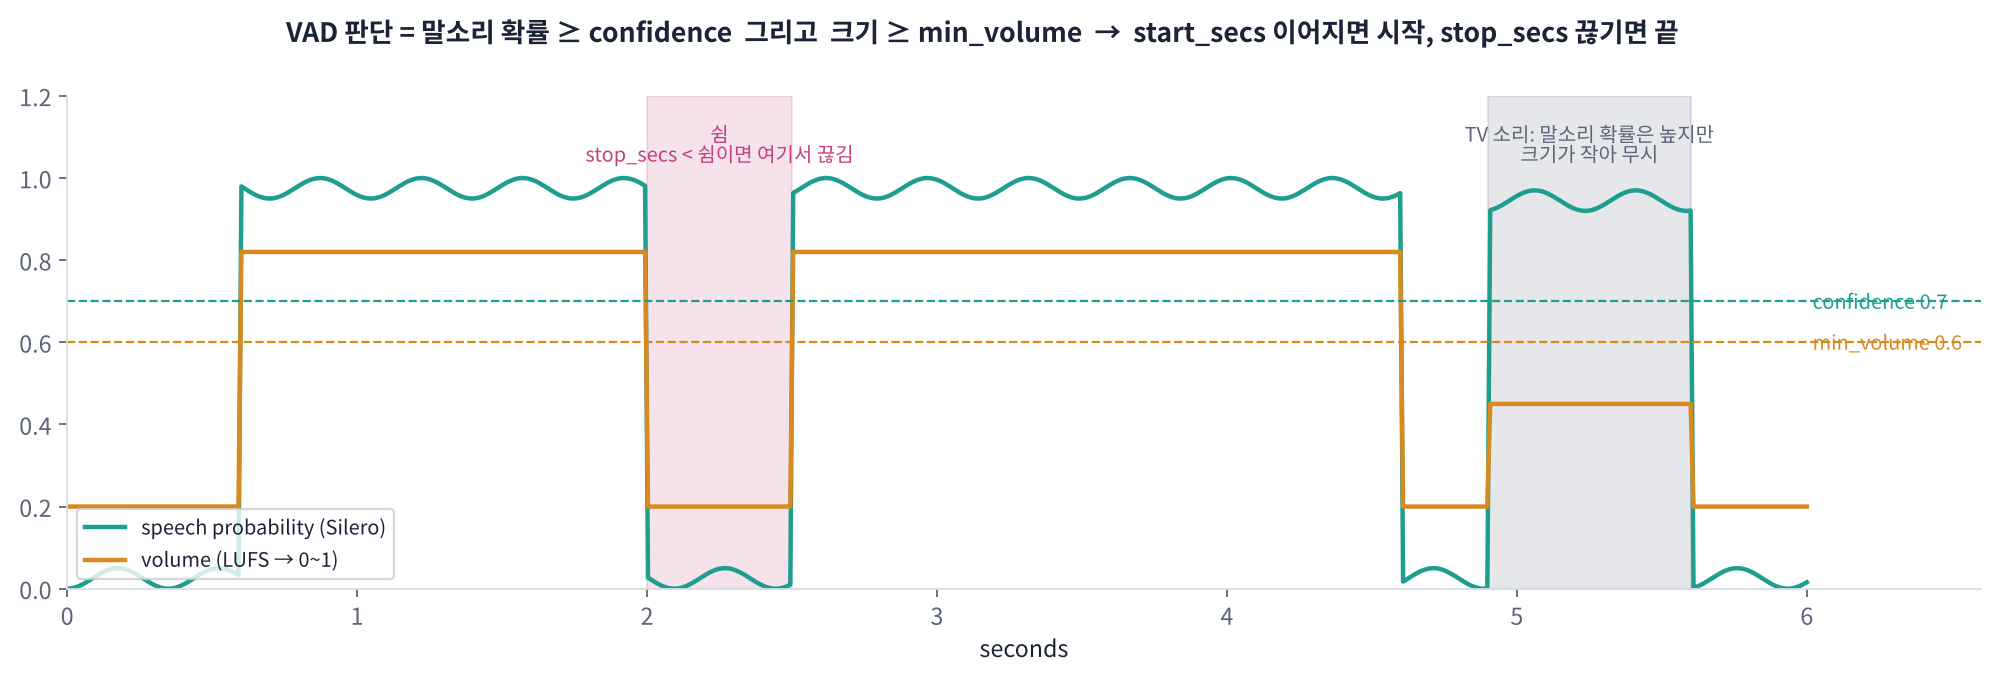

| 손잡이 (`VADParams`) | 기본값 | 뜻 | 키우면 |
|---|---|---|---|
| `confidence` | 0.7 | Silero가 '말소리'라고 확신하는 정도의 기준 | 잡음에 덜 속지만 작은 말을 놓침 |
| `start_secs` | 0.2 | 이만큼 말소리가 이어져야 '말 시작' | 기침 · '음'에 덜 반응, 대신 시작 감지가 늦음 |
| `stop_secs` | 0.2 | 이만큼 조용해야 '말 끝' | 말 중간 쉼을 덜 자르지만 끝 감지가 늦음 |
| `min_volume` | 0.6 | 이보다 작은 소리는 말이 아님 | 먼 소리 · TV를 무시하지만 작게 말하는 사람을 놓침 |

> 💬 **쉽게 말하면**: VAD는 '말소리 같은가(confidence)'와 '충분히 큰가(min_volume)'를 둘 다 만족할 때만 말로 보고, 그 상태가 `start_secs` 이어지면 시작, `stop_secs` 끊기면 끝으로 판단합니다.

> 📐 **핵심 식 하나**: **volume = (LUFS + 110) / 100** (−110 LUFS = 0, −10 LUFS = 1). 기본 `min_volume=0.6`은 **−50 LUFS**, 0.75는 −35 LUFS입니다.

> ⚠️ Pipecat은 턴 판단 · 지연 수치를 `stop_secs=0.2` 기준으로 맞춰 두었습니다. 쉼을 견디려면 `stop_secs`를 늘리기보다 **턴 판단(Part 2)** 에서 기다리는 것이 권장 방법입니다. 그래서 0.2가 아닌 값을 주면 경고가 나옵니다.

> 🎬 **애니메이션 D28-2:** [VAD 손잡이](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#vad) — confidence · start · stop · min_volume을 바꾸며 말소리 구간 보기
> 🎬 **애니메이션 D28-3:** [min_volume과 TV 소리](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#volume) — 배경 소리 크기와 기준값으로 무엇이 '말'이 되는지 보기

### 🧩 빈칸 실습 1: '말 끝' 기준 시간
쉼이 있는 말(`PAUSED`)에 '조용해야 하는 시간'을 바꿔 가며 VAD가 말소리 구간을 몇 개로 나누는지 봅니다. `VADParams`에서 그 손잡이 이름은?

> ## 🎤 강사 스크립트 · Part 1 VAD 손잡이  ⏱️ 7분
>
> 🎯 **VAD = 말소리 같은가(confidence) × 충분히 큰가(min_volume) × 얼마나 이어지나(start · stop).**
>
> 🖥️ [D28-2 VAD 손잡이](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#vad): stop_secs를 0.2 → 1.2로(쉼에서 안 쪼개짐, 대신 '말 끝 감지 지연' 1.2초), start_secs 0 → 기침이 말이 됨.
>
> 🖥️ [D28-3 min_volume · TV](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#volume): 기준 0.6 → 0.75.

In [ ]:
# 🧩 빈칸 실습 1: stop_secs를 바꾸며 쉼이 있는 말을 VAD에 흘려보내기
VAD_EV = ["VADUserStartedSpeakingFrame", "VADUserStoppedSpeakingFrame"]

async def vad_events(y, params):                         # 소리 하나를 VAD에 실시간으로 흘려보내고 말 시작 · 끝 기록
    rec = Recorder("VAD 뒤")
    await run_frames([VADProcessor(vad_analyzer=SileroVADAnalyzer(params=params)), rec], feed=mic(np.concatenate([y, silence(1.5)])))   # 뒤 1.5초 더: 긴 stop_secs도 끝을 볼 수 있게
    T = rec.table()
    return T[T["Frame"].isin(VAD_EV)].reset_index(drop=True)

def speech_end(y, thr=0.02):                             # 실제로 소리가 끝난 시각(초)
    nz = np.flatnonzero(np.abs(y) > thr); return nz[-1] / SR if len(nz) else 0

rows = []
for s in [0.2, 0.5, 1.2]:                                # ✏️ 다른 값도 넣어 보세요 (PAUSE = 0.9초)
    params = VADParams(____=s)                                                    # 빈칸 1
    ev = await vad_events(PAUSED, params)
    stops = ev[ev["Frame"] == "VADUserStoppedSpeakingFrame"]["시각"]
    rows.append(dict(stop_secs=s, 말소리_구간=int((ev["Frame"] == "VADUserStartedSpeakingFrame").sum()),
                     마지막_말끝_감지_초=round(stops.max(), 2) if len(stops) else None, 실제_말끝_초=round(speech_end(PAUSED), 2)))
VADT = pd.DataFrame(rows); VADT["기다림_초"] = (VADT["마지막_말끝_감지_초"] - VADT["실제_말끝_초"]).round(2)
display(VADT)
check(params.stop_secs == 1.2 and len(VADT) == 3, hint="빈칸 1 = stop_secs")

> ## 🎤 강사 스크립트 · 🧩 빈칸 1  ⏱️ 7분
>
> 🆘 "조용해야 하는(stop) 시간(secs)" → `stop_secs`.
>
> ✅ 표 3줄(쉼 0.9초): 0.2 → 구간 2 · 기다림 약 0.2초, 0.5 → 2 · 약 0.5초, 1.2 → 1 · 약 1.2초, ✅. 경고 줄(recommended default)이 나오는 것은 정상.
>
> ❓ "1.2로 두면 쉼은 해결인데 무엇을 잃었죠?" → 모든 턴이 1초씩 느려짐.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
params = VADParams(stop_secs=s)   # 빈칸 1
```

**해설**: `stop_secs`가 쉼(`PAUSE` 0.9초)보다 **짧으면** 말이 두 구간으로 쪼개지고, 길면 한 구간이 됩니다. 대신 '마지막 말 끝'을 알아채는 시각이 그만큼 늦어집니다(기다림 열). VAD만으로 쉼을 견디게 하면 **모든 턴이 그만큼 느려지는** 것이죠. 그래서 Pipecat은 VAD는 짧게(0.2초) 두고, '진짜 턴이 끝났나'는 Part 2의 턴 판단 전략에 맡기는 구조를 권합니다. 표의 `시각`은 Recorder 기준이라 실제 소리 시각과 수십 ms 차이가 있습니다.

</details>

### 🧩 빈칸 실습 2: 배경 TV 소리 걸러 내기
사용자가 말하기 전 **작은 TV 소리**(다른 사람 목소리)가 깔려 있는 장면입니다. 크기 기준을 올려 TV를 무시하게 해 보세요. 그 손잡이 이름은?

In [ ]:
# 🧩 빈칸 실습 2: min_volume으로 작은 배경 목소리 무시하기
from pipecat.audio.utils import calculate_audio_volume
TV_GAIN = 0.03                                           # ✏️ TV 소리 크기 (0.01 ~ 0.2)
ROOM = scene(TV * TV_GAIN, 0.4, user_tts(A + " " + B), tail=1.0)
tv_end = 0.5 + len(TV) / SR                              # TV 소리가 끝나는 시각 (앞 0.5초 조용함 포함)
pcm = lambda y: (np.clip(y, -1, 1) * 32767).astype(np.int16).tobytes()
display(pd.DataFrame([dict(소리="TV (작게)", volume=round(calculate_audio_volume(pcm(TV * TV_GAIN), SR), 3)),
                      dict(소리="사용자", volume=round(calculate_audio_volume(pcm(ROOM[int(tv_end * SR) + SR // 2:]), SR), 3))]))
rows = []
for mv in [0.6, 0.75, 0.85]:                             # ✏️
    p = VADParams(____=mv)                                                         # 빈칸 2
    ev = await vad_events(ROOM, p)
    st = ev[ev["Frame"] == "VADUserStartedSpeakingFrame"]["시각"]
    rows.append(dict(min_volume=mv, 말시작_횟수=len(st), 첫_말시작_초=round(st.min(), 2) if len(st) else None,
                     TV를_말로_봄=bool(len(st) and st.min() < tv_end)))
display(pd.DataFrame(rows)); play(ROOM, SR, f"TV 소리(크기 {TV_GAIN}) 뒤 사용자 말")
check(p.min_volume == 0.85 and len(rows) == 3, hint="빈칸 2 = min_volume")

> ## 🎤 강사 스크립트 · 🧩 빈칸 2  ⏱️ 7분
>
> 🆘 "최소(min) 크기(volume)" → `min_volume`.
>
> ✅ volume 표: TV 0.6 ~ 0.7, 사용자 0.9 이상. 기준표: 0.6이면 TV를 말로 봄(True), 0.75 · 0.85면 False, ✅.
>
> 🎧 TV 섞인 소리를 반 전체가 듣기: "사람 귀에는 작게라도 분명히 말소리죠. Silero도 그렇게 듣습니다. 그래서 크기로 거릅니다."

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
p = VADParams(min_volume=mv)   # 빈칸 2
```

**해설**: Silero는 **사람 목소리면 크기와 상관없이** 말소리라고 합니다(TV 속 아나운서도 사람). 그래서 '말소리인가(confidence)'만으로는 TV를 못 거르고, **크기 기준(`min_volume`)** 이 필요합니다. 위 표의 volume 값 사이에 기준을 두면 TV는 무시하고 사용자 말만 잡습니다. 단, 기준을 너무 올리면 **작게 말하는 어르신 · 먼 마이크**를 놓칩니다. 실제 서비스는 마이크 쪽 **잡음 제거 · 음원 분리**(D4 DeepFilterNet, Pipecat의 Krisp · RNNoise 필터)를 앞에 두는 것이 더 근본적인 방법입니다.

</details>

**❓ 생각해 보기**: 콜센터 전화(8 kHz, 시끄러운 거리)와 조용한 사무실의 웹 브라우저(16 kHz 헤드셋) 중 어디에 min_volume을 더 높게 둘까요? 그리고 무엇을 함께 바꾸겠습니까?

<details>
<summary>답 보기</summary>

**거리 전화**는 배경 소음이 크므로 `min_volume` · `confidence`를 높이고 `start_secs`도 조금 늘려 경적 · 짧은 소음에 덜 반응하게 합니다. 대신 작게 말하는 사람을 놓칠 수 있으니 **잡음 제거 필터**를 입력 Transport에 함께 겁니다. **헤드셋 사무실**은 기본값으로 충분하고, 오히려 기준을 낮춰 작은 목소리를 놓치지 않게 합니다. 정답은 하나가 아니라 **현장 녹음으로 재 보고 정하는 것**입니다(오늘 표를 만드는 이유).

</details>

> 📝 **워크시트 1교시** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day28/worksheet.html) — VAD 손잡이 10문항

> ## 🎤 강사 스크립트 · 토론 + 워크시트 1교시  ⏱️ 6분
>
> ❓ 거리 전화 vs 헤드셋 → 정답은 현장 녹음으로 재기.
>
> 🖥️ [worksheet.html 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day28/worksheet.html).

## Part 2. Turn Detection: '조용하면 끝' vs '말을 듣고 판단'

VAD의 '말 끝'은 **소리가 멈췄다**는 뜻일 뿐, **할 말이 끝났다**는 뜻은 아닙니다. 턴(turn)이 끝났는지는 사용자 쪽 Aggregator의 **stop 전략**이 정합니다.

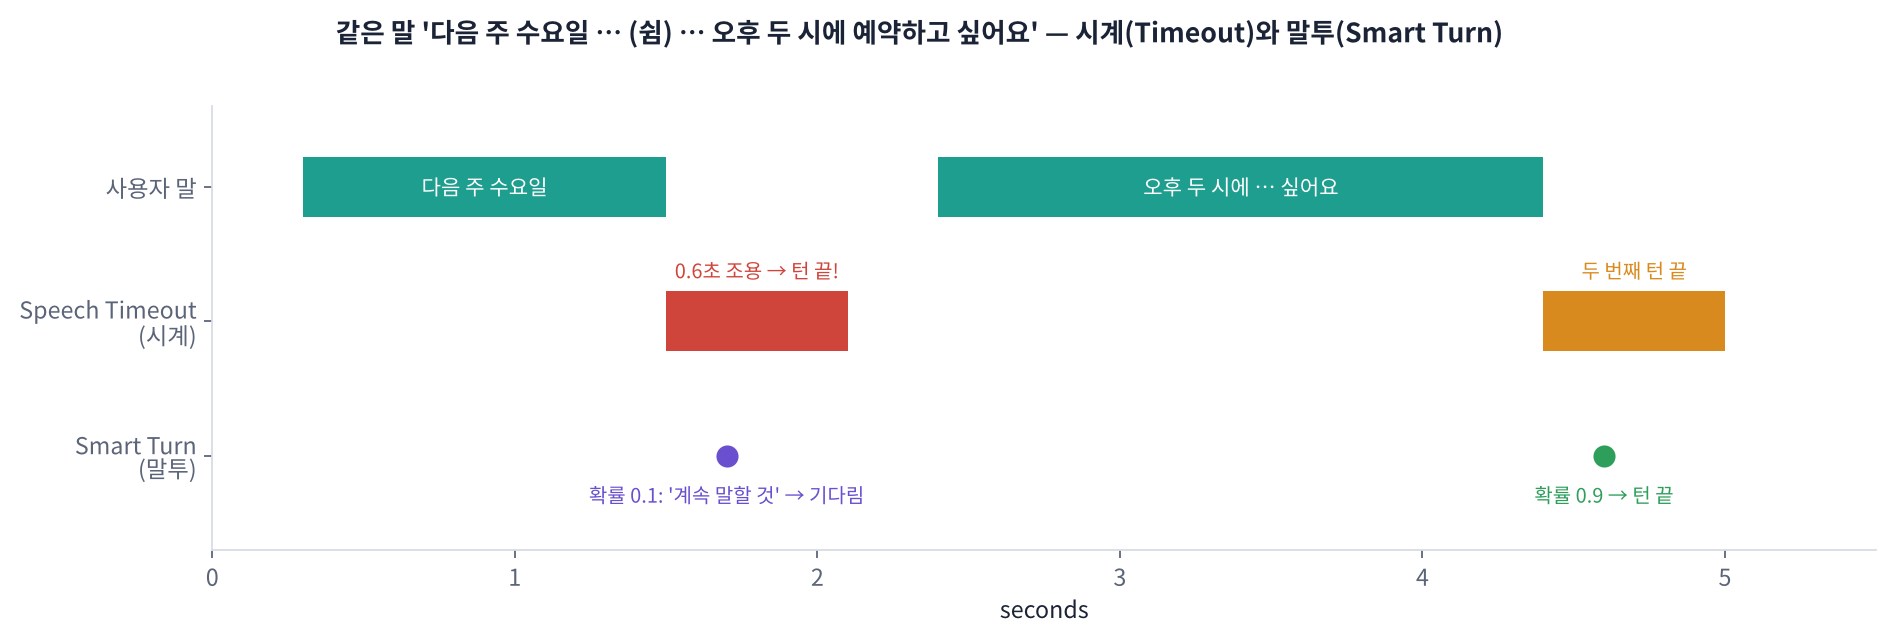

| 전략 | 판단 근거 | 장점 | 단점 |
|---|---|---|---|
| `SpeechTimeoutUserTurnStopStrategy` (D27) | VAD 말 끝 뒤 **N초 조용하면** 끝 | 단순 · 빠름 · 모델 없음 | 쉼에서 말을 자르거나, N을 키우면 모든 턴이 느려짐 |
| `TurnAnalyzerUserTurnStopStrategy` + **Smart Turn** | 마지막 8초 소리를 보고 **'말을 끝냈나' 확률**을 모델이 예측 | 억양 · 말끝('~요' vs '~에')을 보고 쉼을 견딤 | 모델 추론 시간 · 언어 · 목소리에 따라 틀림 |

> 💬 **쉽게 말하면**: Speech Timeout은 **시계**를 보고, Smart Turn은 **말투**를 듣고 판단합니다.

> 🍎 **비유: 무전기 "오버".** 무전에서는 "오버"라고 해야 상대가 말합니다. Smart Turn은 사람이 "오버"를 말하지 않아도 **말꼬리의 억양**으로 "오버"인지 알아채려는 모델입니다.

**Smart Turn v3.2**는 Pipecat 팀이 공개한 오픈 모델(Whisper 인코더 기반, CPU에서 수십 ms)이며 Pipecat 패키지에 ONNX 파일로 들어 있습니다. 기본 턴 판단도 이 모델입니다(D27에서는 일부러 Speech Timeout으로 바꿨음).

> 🎬 **애니메이션 D28-4:** [턴 판단 두 가지](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#turn) — 쉼이 있는 말에서 시계 vs 말투가 언제 턴을 끝내는지 보기

### 🧩 빈칸 실습 3: Smart Turn이 보는 '말 끝 확률'
Pipecat에 들어 있는 로컬 Smart Turn v3 분석기 클래스 이름은? (`pipecat.audio.turn.smart_turn.local_smart_turn_v3`)

> ## 🎤 강사 스크립트 · Part 2 턴 판단  ⏱️ 6분
>
> 🎯 **시계(Timeout) vs 말투(Smart Turn).**
>
> 🖥️ [D28-4 턴 판단 두 가지](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#turn): 쉼 0.9초에서 Timeout은 2턴(잘림), Smart Turn은 1턴. 'Smart Turn 첫 부분 확률'을 0.6으로 올리면 Smart Turn도 잘림 → "모델이 틀리면 똑같이 실수".
>
> 🍎 무전기 "오버".

In [ ]:
# 🧩 빈칸 실습 3: Smart Turn에게 '말을 끝냈나?' 물어보기
from pipecat.audio.turn.smart_turn.local_smart_turn_v3 import LocalSmartTurnAnalyzerV3
st = ____(sample_rate=SR)                                                          # 빈칸 3
CLIPS = {"쉼 없이 끝까지 (…예약하고 싶어요)": FULL, "말하다 멈춤 (…오후 두 시에)": CUT,
         "쉼 앞부분만 (다음 주 수요일)": scene(user_tts(A)), "쉼 포함 전체": PAUSED}
rows = []
for name, y in CLIPS.items():
    t = time.perf_counter(); r = st._predict_endpoint(y.astype(np.float32)); ms = (time.perf_counter() - t) * 1000
    rows.append(dict(소리=name, 말끝_확률=round(float(r["probability"]), 3), 판정="끝" if r["prediction"] == 1 else "계속 말할 것", 추론_ms=round(ms, 1)))
STP = pd.DataFrame(rows); display(STP)
check(isinstance(st, LocalSmartTurnAnalyzerV3) and STP["말끝_확률"].between(0, 1).all(), hint="빈칸 3 = LocalSmartTurnAnalyzerV3")

> ## 🎤 강사 스크립트 · 🧩 빈칸 3  ⏱️ 7분
>
> 🆘 "로컬(Local) · 스마트 턴(SmartTurn) · 분석기(Analyzer) · 버전 3" → `LocalSmartTurnAnalyzerV3`.
>
> ✅ 예상: '쉼 없이 끝까지' 0.8 이상, '말하다 멈춤' · '쉼 앞부분만' 0.3 이하, 추론 수십 ~ 100 ms(CPU), ✅.
>
> ⚠️ 합성 목소리라 순서가 뒤집혀도 정상 범위. "그래서 현장 녹음으로 확인한다"로 연결.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
st = LocalSmartTurnAnalyzerV3(sample_rate=SR)   # 빈칸 3
```

**해설**: `_predict_endpoint()`는 밑줄로 시작하는 **내부용** 메서드라 수업에서 속을 들여다보는 용도로만 씁니다(파이프라인에서는 전략이 알아서 부름). 모델은 **소리만** 봅니다(글자를 보지 않음). '오후 두 시에'처럼 문장이 덜 끝난 소리에서 확률이 낮고, '~싶어요'로 끝난 소리에서 높게 나오면 의도대로 동작하는 것입니다. 합성 목소리 · 한국어에서는 틀릴 수 있으니 **현장 녹음으로 확인**하세요. 추론 시간(CPU 수십 ms)은 턴마다 더해지는 비용입니다.

</details>

### 🧩 빈칸 실습 4: 두 전략으로 같은 말 들어 보기
쉼이 있는 말을 사용자 쪽 Aggregator에 흘려보내고, **턴이 몇 번 끝났는지**(= `LLMContextFrame`이 LLM 쪽으로 몇 번 나갔는지)와 **대화 기록의 user 메시지**를 비교합니다. Smart Turn을 쓰는 stop 전략 클래스 이름은?

In [ ]:
# 🧩 빈칸 실습 4: Speech Timeout vs Smart Turn (LLM 없이 사용자 쪽만)
from pipecat.turns.user_stop.turn_analyzer_user_turn_stop_strategy import TurnAnalyzerUserTurnStopStrategy
SMART_STOP = ____(turn_analyzer=LocalSmartTurnAnalyzerV3())                         # 빈칸 4
STRATS = {"Speech Timeout 0.6초": [SpeechTimeoutUserTurnStopStrategy(user_speech_timeout=0.6)], "Smart Turn": [SMART_STOP]}
rows, T_END = [], speech_end(PAUSED)
for name, stop in STRATS.items():
    context, ua, _ = make_bot(stop=stop)
    rec = Recorder("LLM 자리")
    await run_frames([VADProcessor(vad_analyzer=SileroVADAnalyzer()), WhisperSTT(), ua, rec],
                     feed=mic(np.concatenate([PAUSED, silence(3.5)])))   # 뒤에 3.5초 조용함: Smart Turn이 '끝 아님'이라 판단해도 결국 끝나게
    T = rec.table(); turns = T[T["Frame"] == "LLMContextFrame"]["시각"].tolist()
    users = [m["content"] for m in context.get_messages() if m["role"] == "user"]
    rows.append(dict(전략=name, 턴_수=len(turns), 턴_끝_시각=[round(t, 2) for t in turns], 실제_말끝=round(T_END, 2),
                     마지막_턴_끝_말끝_뒤=round(turns[-1] - T_END, 2) if turns else None, user_메시지=users))
TURN_CMP = pd.DataFrame(rows); display(TURN_CMP)
check(isinstance(SMART_STOP, TurnAnalyzerUserTurnStopStrategy) and len(TURN_CMP) == 2, hint="빈칸 4 = TurnAnalyzerUserTurnStopStrategy")

> ## 🎤 강사 스크립트 · 🧩 빈칸 4  ⏱️ 8분
>
> 🆘 "turn 분석기(TurnAnalyzer)를 쓰는 · 사용자 턴 · 멈춤 전략" → `TurnAnalyzerUserTurnStopStrategy`.
>
> ✅ (약 20초) Speech Timeout: 턴 2개(첫 턴 끝이 실제 말 끝보다 앞), user 메시지 2개. Smart Turn: 턴 1개, 마지막 턴 끝이 말 끝 뒤 0.3 ~ 3초(판단이 '계속'이면 3초 안전장치), ✅.
>
> 🗣️ "Timeout 쪽 첫 user 메시지가 '다음 주 수요일'뿐이라면, LLM은 '몇 시로 해 드릴까요?'라고 답했을 겁니다. 사용자는 말을 끊긴 거죠."

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
SMART_STOP = TurnAnalyzerUserTurnStopStrategy(turn_analyzer=LocalSmartTurnAnalyzerV3())   # 빈칸 4
```

**해설**: stop **전략**(언제 턴을 끝낼지 정하는 규칙)과 turn **분석기**(모델)가 나뉘어 있어서, 분석기만 다른 것(원격 Smart Turn · Krisp 등)으로 바꿀 수 있습니다. 표에서 Speech Timeout은 VAD 말 끝(0.2초) + 0.6초 = **0.8초**보다 긴 쉼(오늘 0.9초)에서 **두 턴으로 쪼개져** user 메시지가 두 개가 됩니다(첫 턴에 LLM이 '수요일 몇 시요?'라고 끼어드는 상황). Smart Turn은 '다음 주 수요일'의 말끝이 덜 끝난 억양이면 기다립니다. '마지막 턴 끝 말끝 뒤' 열이 **턴 판단이 응답 지연에 더하는 시간**입니다(STT가 느리면 그 시간도 섞임). 쪼개진 경우 첫 턴 끝 시각이 실제 말 끝보다 **앞**에 있습니다.

</details>

**❓ 생각해 보기**: Smart Turn이 '끝 아님'이라고 판단했는데 사용자가 정말로 말을 끝냈다면 어떻게 될까요? Pipecat은 이것을 어떻게 막을까요?

<details>
<summary>답 보기</summary>

비서가 **아무 말도 안 하고 기다리는** 어색한 상황이 됩니다. 그래서 Smart Turn에는 안전장치가 있습니다: 모델이 '계속'이라고 해도 **일정 시간(기본 3초) 조용하면 끝**으로 봅니다(`SmartTurnParams.stop_secs`). 즉 최악의 경우 3초, 보통은 수백 ms 안에 끝납니다. 실제 서비스에서는 이 대기 시간을 줄이고, 턴이 너무 일찍 끝났을 때는 **끼어들기(Part 3)** 로 사용자가 이어 말할 수 있게 해서 두 실수를 모두 줄입니다.

</details>

> 📝 **워크시트 2교시** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day28/worksheet.html) — Turn Detection 10문항

> ## 🎤 강사 스크립트 · 토론 + 워크시트 2교시  ⏱️ 6분
>
> ❓ Smart Turn이 틀려서 기다리기만 하면? → 3초 안전장치 + 너무 빨리 끝냈을 때는 끼어들기로 회복(다음 Part로 연결).
>
> 🖥️ [worksheet.html 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day28/worksheet.html).

## Part 3. Interruption (Barge-in): 비서 말을 끊고 들어오기

사람끼리는 상대가 말하는 도중에도 "잠깐만요"라고 끼어듭니다. 음성 비서도 **말하는 중에 귀를 열어 두고**, 사용자가 말을 시작하면 **곧바로 입을 다물어야** 합니다.

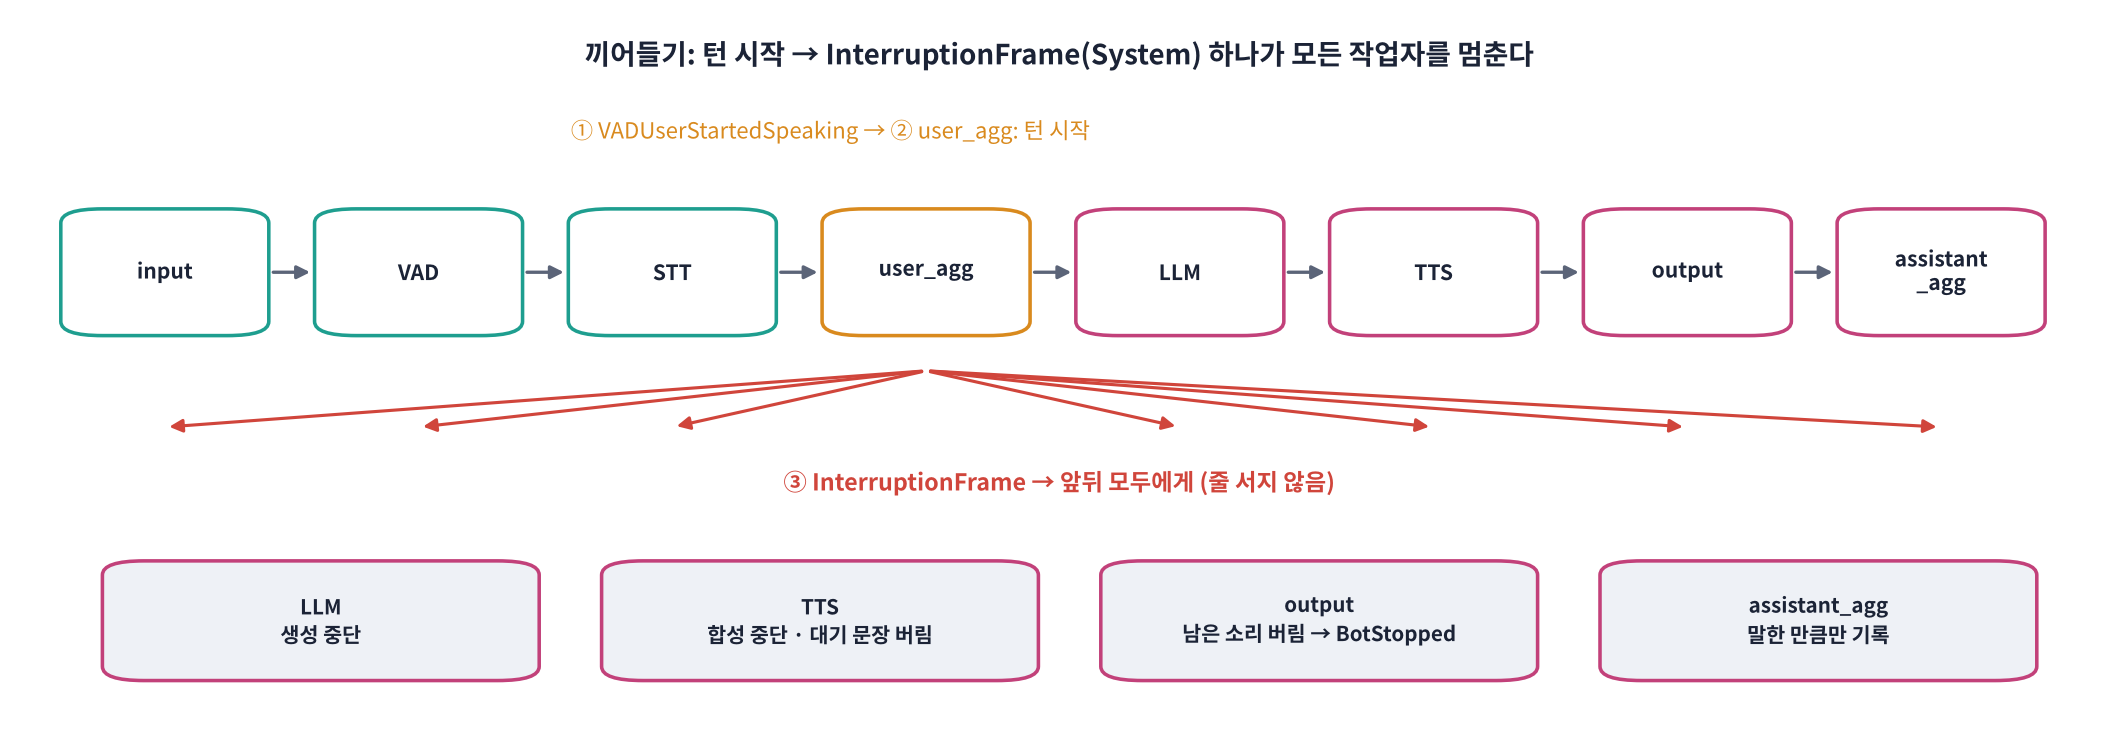

👣 **한 단계씩: 끼어들기 한 번**
1. 비서가 말하는 중(출력 Transport가 `BotStartedSpeakingFrame`을 앞뒤로 알림, D27 Part 6)
2. 사용자 말소리 → VAD `VADUserStartedSpeakingFrame`
3. 사용자 쪽 Aggregator의 **start 전략**이 턴 시작으로 판단 → **`InterruptionFrame`** 을 파이프라인 전체에 뿌림 (SystemFrame이라 줄을 서지 않음, D27 Part 1)
4. 모든 작업자가 **처리 중이던 일과 대기 줄을 버림**: LLM 생성 중단 · TTS 중단 · 출력 Transport의 남은 소리 버림 → `BotStoppedSpeakingFrame`
5. 봇 쪽 Aggregator는 **실제로 내보낸 부분까지만** 기록(D27 빈칸 8에서 맨 끝에 둔 이유)
6. 사용자 말이 끝나면 평소처럼 새 턴 → 새 답

> 💬 **쉽게 말하면**: `InterruptionFrame` 하나가 "모두 멈춰!"를 외치면, 공장 라인의 모든 작업자가 손에 든 상자를 내려놓습니다.

> 📐 **핵심 식 하나**: **끼어들기 반응 시간 = VAD 시작 판단(start_secs 0.2초) + 전파 + 출력 버퍼에 남은 소리**. 사람은 0.5초 안에 멈추길 기대합니다.

오늘은 비서가 통화 시작에 긴 **안내 멘트**(`GREET`, 녹취 고지 포함)를 하고, 사용자가 2초쯤 뒤에 "잠깐만요, 예약만 할게요"라고 끼어드는 장면을 세 가지 설정으로 돌립니다.

> 🎬 **애니메이션 D28-5:** [끼어들기 타임라인](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#barge) — InterruptionFrame이 퍼지며 각 작업자가 멈추는 모습

### 🧩 빈칸 실습 5: 끼어들기 신호 잡기
Observer로 끼어들기 순간을 기록합니다. 사용자 쪽 Aggregator가 "모두 멈춰!"로 뿌리는 Frame 이름은?

> ## 🎤 강사 스크립트 · Part 3 끼어들기  ⏱️ 6분
>
> 🎯 **턴 시작 → InterruptionFrame 하나 → 모두 멈춤 → 말한 만큼만 기록.**
>
> 🖥️ [D28-5 끼어들기 타임라인](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#barge): ▶ 재생, 출력 버퍼를 0 → 500 ms로 바꾸며 반응 시간 변화.
>
> 🗣️ "D27 Part 1에서 InterruptionFrame이 System이었던 이유가 이것입니다. 줄 서서 기다리면 멈추라는 명령이 늦게 도착하니까요."

In [ ]:
# 🧩 빈칸 실습 5: 끼어들기 기록 Observer + 설정 A (기본: 끼어들기 켜짐)
class BargeLog(BaseObserver):
    WATCH = (VADUserStartedSpeakingFrame, UserStartedSpeakingFrame, BotStartedSpeakingFrame, BotStoppedSpeakingFrame)
    def __init__(self, **kwargs):
        super().__init__(**kwargs); self.rows = []
    async def on_push_frame(self, data: FramePushed):
        f = data.frame
        if not data.first_push or data.direction != FrameDirection.DOWNSTREAM: return
        if isinstance(f, ____) or isinstance(f, self.WATCH):                          # 빈칸 5
            self.rows.append(dict(t_abs=time.perf_counter(), Frame=type(f).__name__, 보낸쪽=data.source.name))
    def table(self, T0):
        T = pd.DataFrame(self.rows)
        if len(T): T.insert(0, "t", (T.pop("t_abs") - T0).round(2))
        return T

def barge_reaction(res):                                 # 사용자 말 시작 → 비서 소리가 멈춘 시각 (클라이언트에서 잰 값)
    onset = res["sent"][0]["말시작"]
    for a, b in bot_spans(res["chunks"]):
        if a <= onset <= b: return round(b - onset, 2)
    return None

async def barge_call(start=None, mute=(), label=""):     # 안내 멘트 2초 뒤 끼어들기 한 통화
    context, ua, aa = make_bot(start=start, mute=mute)
    log = BargeLog()
    res = await ws_call(lambda tr: [tr.input(), VADProcessor(vad_analyzer=SileroVADAnalyzer()), WhisperSTT(), ua, make_llm(), KoTTS(), tr.output(), aa],
                        voices=[INTERRUPT], greet=GREET, barge_at=2.0, observers=[log])
    res.update(context=context, log=log.table(res["T0"]), label=label, reaction=barge_reaction(res))
    return res

RES_A = await barge_call(label="A. 기본 (끼어들기 켜짐)")
plot_call(RES_A, RES_A["label"])
display(RES_A["log"])
print("끼어들기 반응(사용자 말 시작 → 비서 소리 멈춤):", RES_A["reaction"] if RES_A["reaction"] is not None else "(사용자가 말을 시작하기 전에 비서 말이 끝남 → barge_at을 줄여 보세요)", "초")
display(pd.DataFrame(RES_A["context"].get_messages())[["role", "content"]])
check(any(RES_A["log"]["Frame"] == "InterruptionFrame") if len(RES_A["log"]) else False, hint="빈칸 5 = InterruptionFrame")

> ## 🎤 강사 스크립트 · 🧩 빈칸 5 · 설정 A  ⏱️ 8분
>
> 🆘 "끼어들기(Interruption) Frame" → `InterruptionFrame`.
>
> ✅ (약 20초) 그림: 분홍 막대가 초록 막대 시작 0.2 ~ 0.5초 뒤에 끊기고, 초록이 끝난 뒤 새 분홍. 기록표: VADUserStarted → UserStarted → InterruptionFrame → BotStopped. 반응 0.2 ~ 0.6초, ✅.
>
> 🎧 끊기는 안내를 같이 듣기는 어려우니(소리는 이어 붙여 저장됨) 그림으로 설명.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
if isinstance(f, InterruptionFrame) or isinstance(f, self.WATCH):   # 빈칸 5
```

**해설**: 타임라인 그림에서 분홍(비서) 막대가 초록(사용자) 막대가 시작된 직후 **끊기면** 성공입니다. 기록표의 순서는 `VADUserStartedSpeakingFrame` → `UserStartedSpeakingFrame` → **`InterruptionFrame`** → `BotStoppedSpeakingFrame`입니다. 대화 기록을 보면 안내 멘트가 **잘린 만큼만 남거나 빠지고**, 이어서 사용자 말과 새 답이 들어갑니다. 반응 시간에는 VAD `start_secs`(0.2초)와, 끼어들기 전 이미 클라이언트로 보낸 소리가 포함됩니다.

</details>

### 🧩 빈칸 실습 6 · 7: 끼어들기를 끄거나, 첫 안내는 끝까지 듣게 하기
- **B. 끼어들기 끄기**: 턴 시작 전략이 '턴 시작'을 판단해도 **InterruptionFrame을 뿌리지 않게** 하는 옵션(빈칸 6). 비서는 끝까지 말하고, 사용자 말은 그 뒤에 처리됩니다.
- **C. Mute**: 비서의 **첫 발화가 끝날 때까지 사용자 입력 자체를 막는** 전략(빈칸 7). 녹취 고지 · 법적 안내처럼 **반드시 끝까지 들려줘야 하는 말**에 씁니다(D34 녹취 고지).

In [ ]:
# 🧩 빈칸 실습 6 · 7: 설정 B (끼어들기 끔) · 설정 C (첫 발화 끝날 때까지 Mute)
from pipecat.turns.user_mute.mute_until_first_bot_complete_user_mute_strategy import MuteUntilFirstBotCompleteUserMuteStrategy
NO_BARGE = [VADUserTurnStartStrategy(____=False), TranscriptionUserTurnStartStrategy(enable_interruptions=False)]   # 빈칸 6
MUTE_FIRST = [____()]                                                                                          # 빈칸 7
RES_B = await barge_call(start=NO_BARGE, label="B. 끼어들기 끔")
RES_C = await barge_call(mute=MUTE_FIRST, label="C. 첫 발화까지 Mute")
for r in [RES_B, RES_C]:
    plot_call(r, r["label"])

def summary(r):
    spans = bot_spans(r["chunks"]); msgs = r["context"].get_messages()
    return dict(설정=r["label"], 말시작_비서멈춤_초=r["reaction"], 첫_비서발화_길이_초=round(spans[0][1] - spans[0][0], 1) if spans else None,
                비서_발화_구간수=len(spans), user_메시지수=sum(m["role"] == "user" for m in msgs),
                대화기록=" | ".join(f"{m['role'][0]}:{str(m['content'])[:18]}" for m in msgs))
BARGE = pd.DataFrame([summary(r) for r in [RES_A, RES_B, RES_C]]); display(BARGE)
check(not NO_BARGE[0]._enable_interruptions and isinstance(MUTE_FIRST[0], MuteUntilFirstBotCompleteUserMuteStrategy),
      hint="빈칸 6 = enable_interruptions, 빈칸 7 = MuteUntilFirstBotCompleteUserMuteStrategy")

> ## 🎤 강사 스크립트 · 🧩 빈칸 6 · 7  ⏱️ 10분
>
> 🆘 빈칸 6: "끼어들기(interruptions)를 켜기(enable)" → `enable_interruptions`. 빈칸 7: "첫 봇 발화가 끝날 때까지 뮤트" → `MuteUntilFirstBotCompleteUserMuteStrategy`.
>
> ✅ (약 40초) 비교표: A 반응 짧음 · 첫 발화 짧음 · user 1개 / B 비서가 멈추지 않음(첫 발화가 안내 전체 길이) · user 1개 / C 안내 전체 · **user 0개**, ✅.
>
> 🖥️ [D28-6 끼어들기 설정](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#mode) 세 칩으로 정리.
>
> 🗣️ "C는 '녹취 고지는 끝까지 들려줘야 한다'는 요구에 맞습니다. D34(운영 · 보안)에서 녹취 고지 의무를 다시 봅니다."

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
NO_BARGE = [VADUserTurnStartStrategy(enable_interruptions=False), TranscriptionUserTurnStartStrategy(enable_interruptions=False)]   # 빈칸 6
MUTE_FIRST = [MuteUntilFirstBotCompleteUserMuteStrategy()]                                                                         # 빈칸 7
```

**해설**: 세 설정을 표로 비교하면(`말시작_비서멈춤_초`: A는 짧고, B · C는 비서가 멈추지 않아 안내가 끝날 때까지의 시간): **A**는 첫 비서 발화가 짧게 끊기고 곧바로 사용자 말에 답합니다. **B**는 안내를 끝까지 말한 **뒤에** 사용자 말에 답합니다(사용자 말은 버리지 않고 턴으로 처리). **C**는 안내를 끝까지 말하고, 그 사이 사용자 말은 **아예 들은 적 없는 것**이 됩니다(user 메시지 0개). C는 녹취 고지처럼 꼭 들려줘야 할 말에는 맞지만, 사용자가 '잠깐만요'를 다시 말해야 하므로 짧은 안내에만 씁니다. Pipecat에는 이 밖에 도구 실행 중에만 막는 `FunctionCallUserMuteStrategy`, 항상 막는 `AlwaysUserMuteStrategy` 등이 있습니다. `_enable_interruptions`는 밑줄로 시작하는 내부 값이라 확인용으로만 읽었습니다.

</details>

**❓ 생각해 보기**: 사용자가 비서 말 도중 '네', '음'처럼 맞장구(backchannel)만 쳐도 A 설정에서는 비서가 멈춥니다. 이것을 어떻게 막을 수 있을까요?

<details>
<summary>답 보기</summary>

① **start 전략을 '단어 수 기준'으로**: `MinWordsUserTurnStartStrategy(min_words=3)`처럼 받아쓴 단어가 3개 이상일 때만 턴 시작(= 끼어들기)으로 봅니다. 대신 STT 시간만큼 반응이 늦어집니다. ② VAD `start_secs`를 0.3 ~ 0.4초로 늘려 짧은 소리에 덜 반응. ③ 끼어들기 판단 자체를 모델로(Pipecat의 backchannel 감지 · Krisp 등). 어느 쪽이든 **'빨리 멈추기'와 '괜히 멈추지 않기'의 맞바꿈**입니다.

</details>

> 📝 **워크시트 3교시** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day28/worksheet.html) — Interruption · Mute 10문항

> ## 🎤 강사 스크립트 · 맞장구 토론 + 워크시트 3교시  ⏱️ 6분
>
> ❓ '네' '음'에 멈추는 문제 → MinWords · start_secs · backchannel 모델. "빨리 멈추기 vs 괜히 멈추지 않기."
>
> 🖥️ [worksheet.html 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day28/worksheet.html).

## Part 4. Metrics: '말 끝 → 첫 소리'를 서비스별로 나눠 재기

D27에서는 Observer 기록을 손으로 뒤져 턴별 시간을 쟀습니다. Pipecat에는 이것을 **정식으로** 재는 장치가 있습니다.

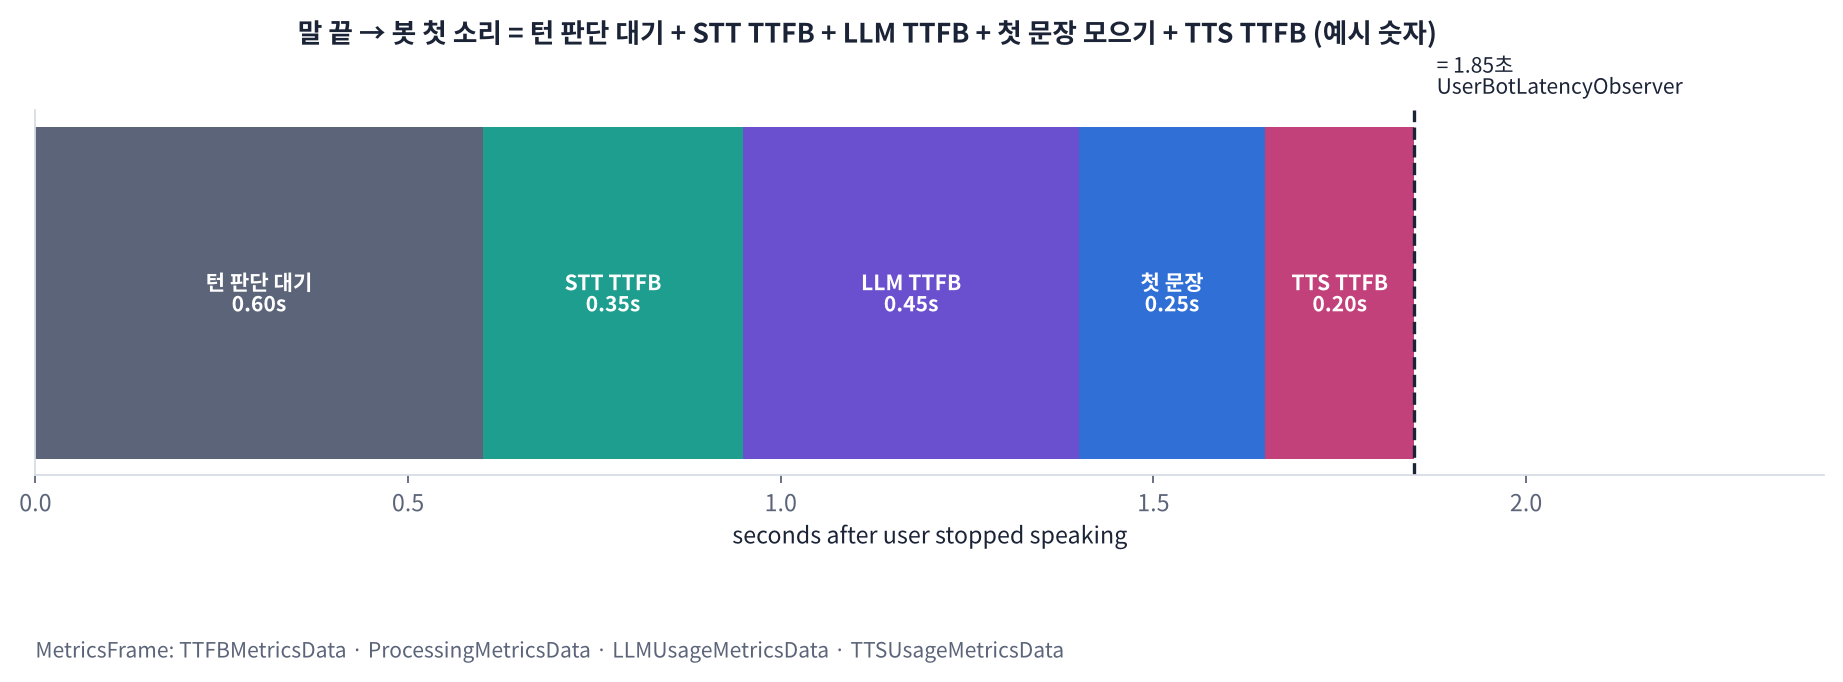

| 장치 | 켜는 법 | 무엇을 주나 |
|---|---|---|
| **MetricsFrame** | `PipelineParams(enable_metrics=True, enable_usage_metrics=True)` + 서비스의 `can_generate_metrics()`가 True | `TTFBMetricsData`(첫 결과까지) · `ProcessingMetricsData`(처리 전체) · `LLMUsageMetricsData`(토큰) · `TTSUsageMetricsData`(글자 수) |
| **UserBotLatencyObserver** | Worker의 `observers=[...]`에 추가 | `on_latency_measured`: 턴마다 **사용자 말 끝 → 봇 첫 소리**(초) |

| 서비스 | TTFB의 뜻 |
|---|---|
| STT | VAD 말 끝 → 받아쓰기 결과 |
| LLM | 요청(LLMContextFrame) → 첫 글자 |
| TTS | 문장 받음 → 첫 소리 조각 |

> 📐 **핵심 식 하나**: **말 끝 → 첫 소리 ≈ 턴 판단 대기 + STT TTFB + LLM TTFB + 첫 문장 모으기 + TTS TTFB**. 가장 큰 덩어리부터 줄입니다.

> 🎬 **애니메이션 D28-7:** [지연 분해](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#metrics) — 턴 한 번의 시간을 서비스별 막대로 나눠 보기

### 🧩 빈칸 실습 8: MetricsFrame 받아 적기
서비스들이 보고하는 성능 수치는 어떤 Frame에 담겨 흐를까요? (SystemFrame의 하나)

> ## 🎤 강사 스크립트 · Part 4 Metrics  ⏱️ 5분
>
> 🎯 **재지 않으면 고칠 수 없다. 전체(UserBotLatency)와 조각(TTFB)을 같이 본다.**
>
> 🖥️ [D28-7 지연 분해](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#metrics): '어느 서비스도 재지 않는 시간' 칸을 강조.

In [ ]:
# 🧩 빈칸 실습 8: Metrics를 모으는 Observer (먼저 TTS 하나로 확인)
from pipecat.metrics.metrics import TTFBMetricsData, ProcessingMetricsData, LLMUsageMetricsData, TTSUsageMetricsData
class MetricsLog(BaseObserver):
    def __init__(self, **kwargs):
        super().__init__(**kwargs); self.rows = []
    async def on_push_frame(self, data: FramePushed):
        f = data.frame
        if isinstance(f, ____) and data.first_push:                                     # 빈칸 8
            for m in f.data:
                v = getattr(m, "value", None)                    # 값이 없는 종류(턴 · TTFA 등)는 건너뜀
                if v is None or (isinstance(v, (int, float)) and not v): continue                       # 시작할 때 0으로 초기화하는 값은 건너뜀
                self.rows.append(dict(t_abs=time.perf_counter(), 서비스=m.processor.split("#")[0], 종류=type(m).__name__.replace("MetricsData", ""),
                                      값=round(v, 3) if isinstance(v, float) else (v if isinstance(v, int) else str(v)[:60])))
    def table(self):
        return pd.DataFrame(self.rows)

mlog = MetricsLog()
await run_frames([KoTTS(), Recorder("끝")], [TTSSpeakFrame(text="네, 다음 주 수요일 오후 2시로 예약해 드릴게요.")], observers=[mlog], metrics=True)
M8 = mlog.table(); display(M8.drop(columns="t_abs") if len(M8) else M8)
check(len(M8) > 0 and (M8["종류"] == "TTFB").any(), hint="빈칸 8 = MetricsFrame")

> ## 🎤 강사 스크립트 · 🧩 빈칸 8  ⏱️ 5분
>
> 🆘 "성능 수치(Metrics) Frame" → `MetricsFrame`.
>
> ✅ 표 2 ~ 3줄: KoTTS Processing · TTFB(수십 ~ 수백 ms) · TTSUsage(글자 수), ✅.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
if isinstance(f, MetricsFrame) and data.first_push:   # 빈칸 8
```

**해설**: `MetricsFrame`은 SystemFrame이라 줄을 서지 않고 바로 흐르고, `data` 안에 여러 수치가 들어 있습니다. KoTTS는 `can_generate_metrics()`를 True로 바꿔 두었기 때문에 부모 `TTSService`가 **TTFB(문장 받음 → 첫 소리)** · **Processing(합성 전체)** · **TTSUsage(읽은 글자 수, 상용 TTS 요금 계산용)** 를 저절로 보고했습니다. `first_push`만 보는 이유는 같은 MetricsFrame이 작업자를 지날 때마다 push되기 때문입니다(D27 Observer).

</details>

### 🧩 빈칸 실습 9: 직접 만든 LLM 서비스에도 TTFB 붙이기
`OpenAILLMService`는 TTFB를 스스로 보고하지만, 어제 만든 `LocalLLM`은 아무것도 보고하지 않습니다. 생성을 시작할 때 `start_ttfb_metrics()`, **첫 글자가 나왔을 때** 짝이 되는 메서드를 부르세요.

In [ ]:
# 🧩 빈칸 실습 9: LocalLLM에 Metrics 붙이기 (D27 LocalLLM + 3줄)
class LocalLLM(FrameProcessor):
    def __init__(self, generate, system_instruction="", **kwargs):
        super().__init__(**kwargs); self.generate = generate
        self.system = [{"role": "system", "content": system_instruction}] if system_instruction else []
    def can_generate_metrics(self):
        return True                                      # ① Metrics 보고 켜기
    async def process_frame(self, frame, direction):
        await super().process_frame(frame, direction)
        if isinstance(frame, LLMContextFrame):
            await self.push_frame(LLMFullResponseStartFrame())
            await self.start_ttfb_metrics()              # ② 시계 시작
            it, first = self.generate(self.system + frame.context.get_messages()), True
            while (piece := await asyncio.to_thread(next, it, None)) is not None:
                if piece and first:
                    await self.____(); first = False                                    # 빈칸 9: ③ 첫 글자에서 시계 멈춤 → MetricsFrame
                if piece: await self.push_frame(LLMTextFrame(text=piece))
            await self.push_frame(LLMFullResponseEndFrame())
        else:
            await self.push_frame(frame, direction)

def slow_gen(msgs):                                      # 확인용: 0.3초 생각하고 답하는 가짜 생성기
    time.sleep(0.3); yield "네, "; yield "알겠습니다."
mlog = MetricsLog()
await run_frames([LocalLLM(slow_gen), Recorder("끝")], [LLMContextFrame(context=LLMContext([{"role": "user", "content": SAY1}]))],
                 observers=[mlog], metrics=True)
M9 = mlog.table(); display(M9.drop(columns="t_abs") if len(M9) else M9)
ttfb = M9[(M9["서비스"] == "LocalLLM") & (M9["종류"] == "TTFB")]["값"] if len(M9) else []
check(len(ttfb) == 1 and 0.25 < float(ttfb.iloc[0]) < 1.0, hint="빈칸 9 = stop_ttfb_metrics")

> ## 🎤 강사 스크립트 · 🧩 빈칸 9  ⏱️ 6분
>
> 🆘 "start의 짝은 stop" → `stop_ttfb_metrics`.
>
> ✅ 표 1줄: LocalLLM TTFB 약 0.30초(가짜 생성기의 0.3초), ✅.
>
> 🗣️ "상용 서비스는 이 세 줄이 이미 들어 있습니다. 직접 만든 서비스도 이렇게 해 두면 같은 표에 나옵니다."

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
await self.stop_ttfb_metrics(); first = False   # 빈칸 9
```

**해설**: `start_ttfb_metrics()` → `stop_ttfb_metrics()` 사이 시간이 **TTFB**로 `MetricsFrame`에 실려 나갑니다(가짜 생성기의 0.3초가 그대로 보임). 같은 방식으로 `start_processing_metrics()` · `stop_processing_metrics()`로 처리 전체 시간도 보고할 수 있습니다. `make_llm()`은 이름으로 `LocalLLM`을 찾으므로, 이 셀 이후의 통화에서는 로컬 LLM도 TTFB를 보고합니다. 끼어들기로 생성이 중단되면 Pipecat이 진행 중인 측정을 취소합니다.

</details>

In [ ]:
# 📊 실제 통화 두 턴: 서비스별 TTFB + UserBotLatencyObserver의 '말 끝 → 봇 첫 소리'
from pipecat.observers.user_bot_latency_observer import UserBotLatencyObserver
async def metrics_call(stop=None, voices=(VOICE1, VOICE2), label=""):
    context, ua, aa = make_bot(stop=stop)
    mlog, lat, LAT = MetricsLog(), UserBotLatencyObserver(), []
    @lat.event_handler("on_latency_measured")
    async def _measured(observer, seconds):
        LAT.append(dict(t_abs=time.perf_counter(), 말끝_봇첫소리_초=round(seconds, 2)))
    res = await ws_call(lambda tr: [tr.input(), VADProcessor(vad_analyzer=SileroVADAnalyzer()), WhisperSTT(), ua, make_llm(), KoTTS(), tr.output(), aa],
                        voices=list(voices), observers=[mlog, lat])
    M = mlog.table()
    if len(M): M.insert(0, "t", (M.pop("t_abs") - res["T0"]).round(2))
    L = pd.DataFrame(LAT)
    if len(L): L.insert(0, "t", (L.pop("t_abs") - res["T0"]).round(2))
    res.update(metrics=M, latency=L, context=context, label=label)
    return res

RES_M = await metrics_call(label="Speech Timeout 0.6초")
M, L = RES_M["metrics"], RES_M["latency"]
display(L)
ttfb = M[M["종류"] == "TTFB"] if len(M) else M
display(ttfb.pivot_table(index="서비스", values="값", aggfunc=["count", "mean", "max"]).round(3) if len(ttfb) else ttfb)
plot_call(RES_M, "두 턴 통화")
if len(L) and len(ttfb):                                 # 턴마다: 그 턴의 봇 첫 소리 직전에 보고된 TTFB들을 모아 막대로
    bounds = [0] + L["t"].tolist(); parts = []
    for k in range(len(L)):
        seg = ttfb[(ttfb["t"] > bounds[k]) & (ttfb["t"] <= bounds[k + 1] + 0.5)]
        parts.append({s: seg[seg["서비스"] == s]["값"].astype(float).iloc[:1].sum() for s in ["WhisperSTT", "LocalLLM", "OpenAILLMService", "KoTTS"]})
    P = pd.DataFrame(parts); P["전체(관측)"] = L["말끝_봇첫소리_초"].values; P["그 밖(턴 판단 대기 등)"] = (P["전체(관측)"] - P.drop(columns="전체(관측)").sum(axis=1)).clip(lower=0)
    P.index = [f"turn {i + 1}" for i in range(len(P))]; display(P.round(2))
    P.drop(columns="전체(관측)").loc[:, lambda d: d.sum() > 0].plot.barh(stacked=True, figsize=(9, 2.2), color=["#1E9E8F", "#6A4FCF", "#6A4FCF", "#C2417A", "#B9C0CC"][: 5])
    plt.xlabel("seconds (user stopped → bot first audio)"); plt.tight_layout(); plt.show()

> ## 🎤 강사 스크립트 · 두 턴 통화 Metrics  ⏱️ 7분
>
> ✅ (약 30초) 지연표 2줄(말끝 → 봇 첫 소리 1 ~ 2초), TTFB 피벗표(WhisperSTT · LLM · KoTTS 각 2회), 턴별 분해표와 막대.
>
> ⚠️ 'STT TTFB'는 VAD 말 끝부터 재므로, STT가 턴 판단 대기(0.6초)보다 오래 걸리면 대기 시간이 STT 안에 숨어 '그 밖'이 작게 나옴(CPU에서 흔함). T4에서는 '그 밖'이 0.2 ~ 0.4초로 보임.

👣 **표 읽기**: `UserBotLatencyObserver`의 값이 D27 Part 5에서 손으로 잰 '말 끝 → 첫 소리'와 같은 개념입니다. 막대그래프의 **'그 밖'** 칸이 어느 서비스도 재지 않는 시간이고, 대부분 **턴 판단 대기**(Speech Timeout 0.6초 또는 Smart Turn 판단)와 첫 문장 모으기입니다.

> 🎬 **애니메이션 D28-8:** [지연 예산 손잡이](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#budget) — VAD · 턴 판단 · 모델 선택을 바꾸며 말 끝 → 첫 소리 예산 맞추기

> ## 🎤 강사 스크립트 · 지연 예산  ⏱️ 3분
>
> 🖥️ [D28-8 지연 예산](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#budget): 목표 1.0초 → Smart Turn + 작은 모델 + 스트리밍 STT · TTS 조합에서만 들어옴. "각 선택의 대가를 같이 읽으세요."

In [ ]:
# ✏️ 설정별 비교: 턴 판단 전략만 바꿔 같은 말 한 턴 (턴 판단이 지연에 얼마나 더하나)
CONFIGS = {"Speech Timeout 0.3초": [SpeechTimeoutUserTurnStopStrategy(user_speech_timeout=0.3)],
           "Speech Timeout 0.6초": [SpeechTimeoutUserTurnStopStrategy(user_speech_timeout=0.6)],
           "Smart Turn": [TurnAnalyzerUserTurnStopStrategy(turn_analyzer=LocalSmartTurnAnalyzerV3())]}
rows = []
for name, stop in CONFIGS.items():                       # ✏️ 쉼이 있는 말(PAUSED)로도 바꿔 보세요
    r = await metrics_call(stop=stop, voices=[VOICE1], label=name)
    L = r["latency"]; users = [m["content"] for m in r["context"].get_messages() if m["role"] == "user"]
    rows.append(dict(설정=name, 말끝_봇첫소리_초=L["말끝_봇첫소리_초"].iloc[0] if len(L) else None, 턴_수=len(users)))
CFG = pd.DataFrame(rows); display(CFG)

> ## 🎤 강사 스크립트 · 설정별 비교  ⏱️ 6분
>
> ✅ (약 45초) 표 3줄. 쉼 없는 말이라 세 설정 모두 1턴이고, 지연 차이는 턴 판단 대기만큼(0.3 ~ 0.5초). STT가 느린 CPU에서는 차이가 작게 나옴.
>
> ❓ "PAUSED로 바꾸면?" → Timeout 0.3 · 0.6은 턴 2개, Smart Turn은 1개. 빠른 설정이 대화를 망가뜨릴 수 있음.

**❓ 생각해 보기**: 목표가 '말 끝 → 첫 소리 p50 1.0초 이하'인데 지금 1.6초입니다. 오늘 배운 손잡이 중 무엇부터 돌리겠습니까?

<details>
<summary>답 보기</summary>

가장 큰 덩어리부터: ① **턴 판단 대기**: Speech Timeout 0.6 → Smart Turn(완결된 말은 수백 ms 안에 끝), ② **LLM TTFB**: 더 작은 · 가까운 모델, 생각 모드 끄기(D22), 프롬프트 짧게, ③ **첫 문장 모으기**: 첫 문장을 짧게 시작하라고 프롬프트에 지시("네, ~"), ④ **STT**: 스트리밍 STT로 말하는 동안 받아쓰기(D8), ⑤ **TTS TTFB**: 스트리밍 TTS. VAD `stop_secs`를 0.2보다 더 줄이는 것은 쉼에서 잘림이 늘어 득보다 실이 큽니다. 그리고 반드시 **한 번이 아니라 여러 턴의 p50 · p90**으로 확인합니다(D21 · D25).

</details>

> 📝 **워크시트 4교시** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day28/worksheet.html) — Metrics · 지연 10문항

> ## 🎤 강사 스크립트 · 토론 + 워크시트 4교시  ⏱️ 6분
>
> ❓ 1.6초 → 1.0초 → 큰 덩어리부터. 반드시 p50 · p90으로.
>
> 🖥️ [D28-9 오늘 정리](https://imguru-mooc.github.io/AI_Voice/day28/animation.html#recap) → [worksheet.html 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day28/worksheet.html).

## Part 5. 정리 · 과제

### 오늘 배운 것
| 개념 | 한 줄 정리 | 코드 |
|---|---|---|
| VAD `stop_secs` | 쉼을 견디게 하지만 모든 턴이 느려짐 → 0.2초 두고 턴 판단에서 기다리기 | `VADParams(stop_secs=0.2)` |
| VAD `min_volume` | 작은 배경 목소리(TV) 무시, 너무 올리면 작은 목소리를 놓침 | `VADParams(min_volume=0.75)` |
| Speech Timeout | 말 끝 뒤 N초 조용하면 턴 끝 (시계) | `SpeechTimeoutUserTurnStopStrategy(user_speech_timeout=0.6)` |
| Smart Turn | 소리의 말끝 억양으로 '끝냈나' 확률 (말투) | `TurnAnalyzerUserTurnStopStrategy(turn_analyzer=LocalSmartTurnAnalyzerV3())` |
| Interruption | 턴 시작 → `InterruptionFrame` → 모두 멈춤 → 말한 만큼만 기록 | `InterruptionFrame` |
| 끼어들기 끄기 | 턴은 처리하되 비서 말을 끊지 않음 | `VADUserTurnStartStrategy(enable_interruptions=False)` |
| Mute | 첫 발화(녹취 고지)가 끝날 때까지 사용자 입력 무시 | `MuteUntilFirstBotCompleteUserMuteStrategy()` |
| Metrics | 서비스별 TTFB · 처리 시간 · 사용량 | `PipelineParams(enable_metrics=True)` · `MetricsFrame` |
| 직접 만든 서비스 | start → stop 짝으로 TTFB 보고 | `start_ttfb_metrics()` · `stop_ttfb_metrics()` |
| 전체 지연 | 턴마다 사용자 말 끝 → 봇 첫 소리 | `UserBotLatencyObserver` · `on_latency_measured` |

### 📝 과제
1. **현장 녹음 튜닝**: 휴대폰으로 '쉬어 가며 말하기' 3개 · 'TV 켜고 말하기' 3개를 녹음해(본인 목소리, 키 · 녹음은 노션에 올리지 않음) Part 1 · 2 표를 다시 만들고, 내 환경에 맞는 `min_volume` · 턴 전략을 정해 근거와 함께 적으세요.
2. **맞장구 실험**: 비서 말 도중 '네'만 말하는 소리를 만들어 설정 A와 `MinWordsUserTurnStartStrategy(min_words=3)`를 비교하세요(끊기는지, 반응 시간은 얼마나 늦어지는지).
3. **지연 예산표**: Part 4 비교를 각 설정 5턴씩 돌려 p50 · p90을 표로 만들고, '말 끝 → 첫 소리 p50 ≤ 1.2초'를 만족하는 조합을 찾으세요.

### ✅ 개념 워크시트 제출
> 📝 **[D28 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day28/worksheet.html)** — 4교시 × 10문항. 4개 탭 채점 → 제출 → 📋 캡처 → 노션. **stop_secs 표 · min_volume 표 · Smart Turn 확률 표 · 턴 비교표 · 끼어들기 비교표 · TTFB 표 · 설정 비교표**도 함께 붙이세요.

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day28/animation.html) — D28-1 ~ D28-9

### 다음 시간 (D29 · LiveKit Agents 기초)
오늘까지는 Transport를 같은 Colab 안의 WebSocket으로만 썼습니다. D29에서는 **LiveKit**의 **Room · Agent Worker · Plugin** 구조로, 브라우저 사용자와 비서가 WebRTC 방에서 만나는 실제 서비스 형태를 만듭니다. 오늘의 VAD · 턴 판단 · 끼어들기 개념이 LiveKit에서도 같은 이름으로 나옵니다.

> ## 🎤 강사 스크립트 · Part 5 정리  ⏱️ 4분
>
> 🎯 **오늘 한 줄: VAD는 짧게, 기다림은 턴 판단에서, 사용자가 말하면 즉시 멈추되 꼭 들려줄 말은 Mute로, 그리고 모든 것을 잰다.**
>
> ➡️ "6주차 후반은 LiveKit입니다. 오늘의 VAD · 턴 판단 · 끼어들기가 LiveKit에서도 같은 이름(turn detection, interruptions)으로 나옵니다. 내일은 브라우저 사용자와 비서가 WebRTC 방에서 만납니다."

In [ ]:
# 📋 오늘의 숫자 (노션에 붙일 표)
SUMMARY = pd.DataFrame([
    dict(항목="LLM", 값=f"{PROVIDER} · {MODELS[PROVIDER]}"),
    *[dict(항목=f"stop_secs {r['stop_secs']}: 말소리 구간 수", 값=r["말소리_구간"]) for _, r in VADT.iterrows()],
    *[dict(항목=f"Smart Turn 확률: {r['소리']}", 값=r["말끝_확률"]) for _, r in STP.iterrows()],
    *[dict(항목=f"{r['전략']}: 턴 수", 값=r["턴_수"]) for _, r in TURN_CMP.iterrows()],
    *[dict(항목=f"{r['설정']}: 사용자 말 시작 → 비서 멈춤 (초)", 값=r["말시작_비서멈춤_초"]) for _, r in BARGE.iterrows()],
    *[dict(항목=f"{r['설정']}: 말 끝 → 봇 첫 소리 (초)", 값=r["말끝_봇첫소리_초"]) for _, r in CFG.iterrows()],
])
display(SUMMARY)

> ## 🎤 강사 스크립트 · 오늘의 숫자  ⏱️ 2분
>
> ✅ 15줄 안팎의 표. 노션에 이 표 + 워크시트 캡처. 녹음 · 키 금지 다시 한 번.